# Casen: Din elregning

Et gennemgående eksempel, der vokser med kurset. Efter hver lektion får casen et nyt kapitel, som bruger *præcis* de værktøjer, du lige har lært - på **rigtige, levende data** om elpriser og dansk økonomi.


> ⚠️ **Vigtigt**: Dette er **ikke** et eksempel på en eksamensopgave. Det er et eksempel på, hvad kursets værktøjer kan, når man sætter dem sammen. Formålet er inspiration og leg - ikke pensum ud over det, I allerede har lært.


### Sådan læser du casen

* Hvert kapitel hører til én lektion og bruger kun værktøjer fra lektionerne til og med den.
* Celler markeret **Maskinrummet** henter data fra internettet (Energi Data Service og Danmarks Statistik). Du behøver ikke forstå koden i dem - de afleverer bare tallene. Kan de ikke nå internettet, bruger de automatisk gemte tal, så notebooken altid virker.
* **Du må ændre i alt!** Ret et tal, og kør cellen igen med Shift+Enter (eller ▶). Hvis senere celler bruger resultatet, så kør også dem igen. Går noget i stykker, vælger du bare *Runtime → Restart session and run all* - så er du tilbage ved start.
* Hvert kapitel slutter med **Drej på knapperne** - konkrete forslag til, hvad du kan ændre. Det er der, det bliver sjovt.


# Kapitel 1 (efter lektion 1): Elprisen i dag

Strøm handles på en børs, time for time, dagen i forvejen. **Spotprisen** er den rå markedspris (før afgifter, transport og moms) - og den svinger voldsomt hen over døgnet. Lad os hente den seneste tilgængelige dags priser for Vestdanmark (DK1) og se på dem med lektion 1's værktøjer: et plot og en hældning.

In [1]:
#@title Maskinrummet: definerer funktionen hent_elpriser(omraade) (du behøver ikke forstå denne celle)
import requests, json
import numpy as np

_GEMTE_PRISER = [0.975, 0.959, 0.958, 0.937, 0.936, 0.984, 1.064, 1.1, 1.068, 0.942, 0.756, 0.496, 0.232, 0.125, 0.162, 0.348, 0.641, 0.863, 1.053, 1.273, 1.468, 1.458, 1.334, 1.239]
_GEMT_DATO = "2026-08-07"
_KILDE_FALLBACK = "gemte DK1-priser (fallback)"

def hent_elpriser(omraade):
    # Henter det nyeste døgns spotpriser (kr/kWh) for et prisområde, fx "DK1"
    try:
        r = requests.get("https://api.energidataservice.dk/dataset/DayAheadPrices",
                         params={"limit": 200, "sort": "TimeDK desc",
                                 "filter": json.dumps({"PriceArea": [omraade]})}, timeout=10)
        rec = r.json()["records"]
        dato = rec[0]["TimeDK"][:10]
        pr_time = {}
        for x in rec:
            if x["TimeDK"][:10] == dato:
                pr_time.setdefault(x["TimeDK"][11:13], []).append(x["DayAheadPriceDKK"])
        priser = [sum(v) / len(v) / 1000 for _, v in sorted(pr_time.items())]
        if len(priser) != 24:
            raise ValueError("ufuldstændigt døgn")
    except Exception:
        # Fallback returnerer ALTID de gemte DK1-priser - uanset hvilket område der blev bedt om.
        # Derfor får kalderen en ærlig kilde-label med retur, så DK2 (eller ethvert andet område)
        # aldrig kan fremstå som ægte data for det område i en graf eller et regnestykke.
        print(f"(Kunne ikke hente live data for {omraade} - viser gemte DK1-priser fra {_GEMT_DATO} i stedet)")
        return np.array(_GEMTE_PRISER), _GEMT_DATO, _KILDE_FALLBACK
    print(f"Hentede friske spotpriser for {dato} ({omraade})")
    return np.array(priser), dato, f"live {omraade}"

In [2]:
# Hent den seneste tilgængelige dags priser for Vestdanmark - funktionen kommer fra maskinrummet ovenfor
elpriser, dato, kilde_dk1 = hent_elpriser("DK1")

timer = np.arange(24)

Hentede friske spotpriser for 2026-08-14 (DK1)


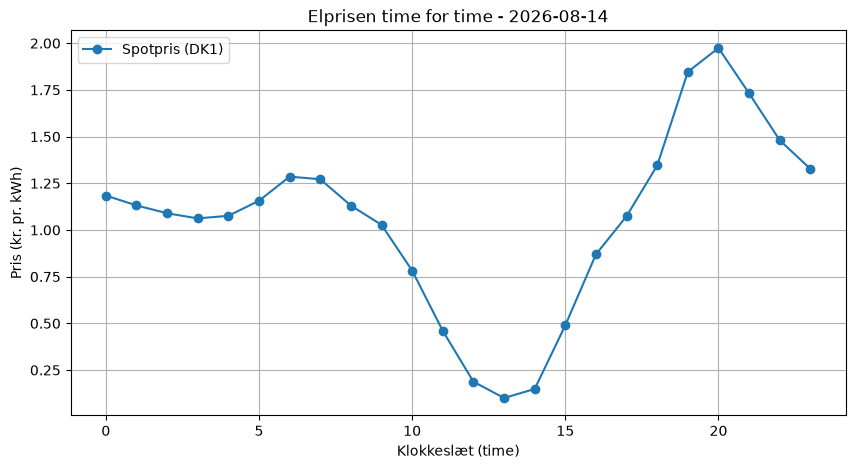

In [3]:
import matplotlib.pyplot as plt

# Plot døgnprofilen
plt.figure(figsize=(10, 5))
plt.plot(timer, elpriser, 'o-', label="Spotpris (DK1)")
plt.title(f"Elprisen time for time - {dato}")
plt.xlabel("Klokkeslæt (time)")
plt.ylabel("Pris (kr. pr. kWh)")
plt.legend()
plt.grid(True)
plt.show()

Elprisen følger samfundets rytme - og årstiden. Om vinteren er morgen- og aftentimerne typisk dyrest. Om sommeren kan solstrøm presse prisen helt i bund midt på dagen - nogle gange endda under nul. Kig på **din** graf: Hvornår er strømmen billigst i dag, og hvor går kurven stejlest op eller ned?

Præcis dét måler en **hældning** - ændringen i pris pr. time, som vi kender fra lektion 1:


In [4]:
# Hældningen mellem to klokkeslæt - som i lektion 1
x1, x2 = 6, 8
haeldning = (elpriser[x2] - elpriser[x1]) / (x2 - x1)

if haeldning > 0:
    print(f"Mellem kl. {x1} og kl. {x2} STIGER prisen: {haeldning:.3f} kr/kWh pr. time")
else:
    print(f"Mellem kl. {x1} og kl. {x2} FALDER prisen: {haeldning:.3f} kr/kWh pr. time")

# Prøv også eftermiddagen, hvor aftensspidsen bygger op
x1, x2 = 14, 20
haeldning = (elpriser[x2] - elpriser[x1]) / (x2 - x1)

if haeldning > 0:
    print(f"Mellem kl. {x1} og kl. {x2} STIGER prisen: {haeldning:.3f} kr/kWh pr. time")
else:
    print(f"Mellem kl. {x1} og kl. {x2} FALDER prisen: {haeldning:.3f} kr/kWh pr. time")

Mellem kl. 6 og kl. 8 FALDER prisen: -0.077 kr/kWh pr. time
Mellem kl. 14 og kl. 20 STIGER prisen: 0.304 kr/kWh pr. time


### Vest mod Øst - og resten af nabolaget

Elmarkedet er delt i prisområder, og funktionen kan hente dem alle - du skal bare give den navnet:

* `"DK1"` - Danmark **vest** for Storebælt (Jylland og Fyn - og Aalborg!)
* `"DK2"` - Danmark **øst** for Storebælt (Sjælland og København)
* `"NO2"` - det sydlige Norge (vandkraft!)
* `"SE3"` og `"SE4"` - det mellemste og sydlige Sverige
* `"DE"` - Tyskland

Lad os sammenligne de to danske områder:


Hentede friske spotpriser for 2026-08-14 (DK2)


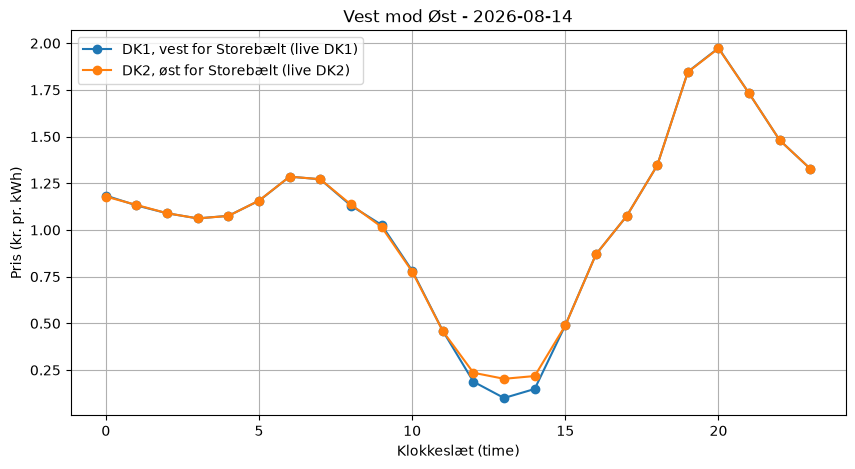

In [5]:
# Hent Østdanmark med samme funktion - bare et andet input
elpriser_dk2, dato_dk2, kilde_dk2 = hent_elpriser("DK2")

if kilde_dk1 == _KILDE_FALLBACK and kilde_dk2 == _KILDE_FALLBACK:
    print("Kunne ikke hente live data - sammenligningen mellem områder springes over i dag.")
else:
    plt.figure(figsize=(10, 5))
    plt.plot(timer, elpriser, 'o-', label=f"DK1, vest for Storebælt ({kilde_dk1})")
    plt.plot(timer, elpriser_dk2, 'o-', label=f"DK2, øst for Storebælt ({kilde_dk2})")
    plt.title(f"Vest mod Øst - {dato}")
    plt.xlabel("Klokkeslæt (time)")
    plt.ylabel("Pris (kr. pr. kWh)")
    plt.legend()
    plt.grid(True)
    plt.show()

Ligger de to kurver næsten oven i hinanden? Det er ikke en fejl: Når elkablerne mellem landsdelene ikke er fyldt op, deler hele Danmark én pris. På dage med meget vind eller stort forbrug skilles kurverne ad - så er der bogstaveligt talt forskel på at bo i Aalborg og i København.


#### Drej på knapperne

* **Prøv nabolaget**: Opret en ny celle (knappen `+ Kode`) og skriv fx `priser_norge, d, kilde = hent_elpriser("NO2")` - og plot dem ligesom ovenfor. Er norsk vandkraft billigere end dansk vind i dag?
* **Mål andre hældninger**: I hældnings-cellen: ret `x1, x2 = 6, 8` til to andre klokkeslæt (fx `10, 13`), og kør cellen igen.
* **Helt uden kode**: Aflæs på graferne - hvornår ville du starte opvaskemaskinen i dag? Og er svaret det samme i øst og vest?

# Kapitel 2 (efter lektion 2): Inflation og dine faste udgifter

Danmarks Statistik måler hver måned, hvad ting koster - **forbrugerprisindekset**. Med lektion 2's værktøjer (eksponentiel vækst og logaritmer) kan vi bruge de *rigtige* inflationstal til at regne på din egen fremtid.


In [6]:
#@title Maskinrummet: henter forbrugerprisindekset fra Danmarks Statistik
_GEMT_CPI = [100, 100.3, 101.4, 102.2, 103, 103.4, 105.4, 113.5, 117.2, 118.8, 121.1]
_CPI_AAR = [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

def hent_forbrugerprisindeks():
    try:
        r = requests.post("https://api.statbank.dk/v1/data",
                          json={"table": "PRIS112", "format": "JSONSTAT",
                                "variables": [{"code": "HOVED", "values": ["1005"]},
                                              {"code": "Tid", "values": [str(a) for a in _CPI_AAR]}]},
                          timeout=10)
        vaerdier = r.json()["dataset"]["value"]
        print("Hentede friske tal fra Danmarks Statistik (tabel PRIS112)")
        return np.array(_CPI_AAR), np.array(vaerdier)
    except Exception:
        print("(Kunne ikke hente live data - viser gemte tal)")
        return np.array(_CPI_AAR), np.array(_GEMT_CPI)

aar, cpi = hent_forbrugerprisindeks()

Hentede friske tal fra Danmarks Statistik (tabel PRIS112)


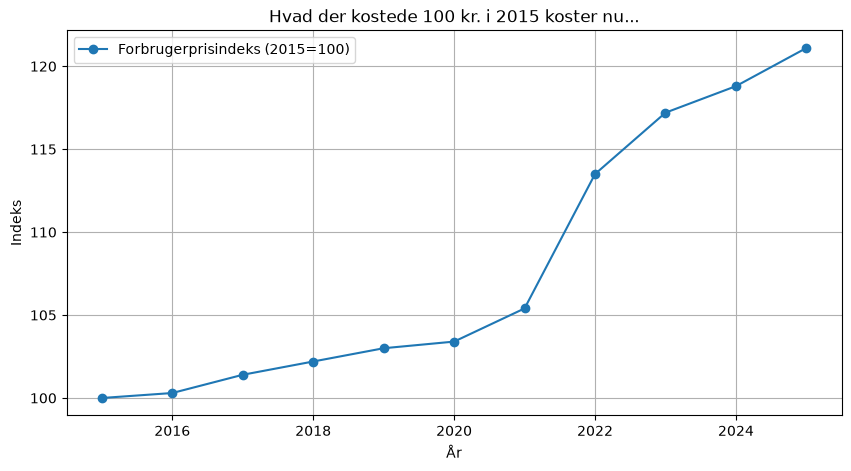

In [7]:
# Plot prisudviklingen (2015 = 100)
plt.figure(figsize=(10, 5))
plt.plot(aar, cpi, 'o-', label="Forbrugerprisindeks (2015=100)")
plt.title("Hvad der kostede 100 kr. i 2015 koster nu...")
plt.xlabel("År")
plt.ylabel("Indeks")
plt.legend()
plt.grid(True)
plt.show()

Læg mærke til, hvordan kurven knækker opad allerede i 2021 - og for alvor stikker af i 2022. Det er energi- og inflationskrisen, direkte i data. Den gennemsnitlige årlige inflation over hele perioden finder vi med en potens (samme logik som renters rente, bare baglæns):


In [8]:
# Gennemsnitlig årlig inflation over perioden
antal_aar = aar[-1] - aar[0]
r = (cpi[-1] / cpi[0]) ** (1 / antal_aar) - 1
print(f"Gennemsnitlig inflation {aar[0]}-{aar[-1]}: {r*100:.2f}% om året")

Gennemsnitlig inflation 2015-2025: 1.93% om året


In [9]:
# Hvad koster dine faste udgifter om 10 år, hvis det fortsætter?
budget = 8000  # dine faste udgifter i kr. pr. måned
om_10_aar = budget * (1 + r) ** 10
print(f"Faste udgifter på {budget} kr./md svarer om 10 år til {om_10_aar:.0f} kr./md i dagens tempo")

# Og hvornår er priserne fordoblet? (logaritmen - lektion 2)
fordobling = np.log(2) / np.log(1 + r)
print(f"Med {r*100:.2f}% årlig inflation fordobles priserne på {fordobling:.0f} år")

Faste udgifter på 8000 kr./md svarer om 10 år til 9688 kr./md i dagens tempo
Med 1.93% årlig inflation fordobles priserne på 36 år


#### Drej på knapperne

* **Dit eget budget**: Ret tallet i linjen `budget = 8000`, og kør cellen igen.
* **Kun kriseårene**: I inflations-cellen: udskift `cpi[0]` med `cpi[5]` og `aar[0]` med `aar[5]`, og kør igen - så regner du kun på 2020-2025. Hvor meget værre var dét?
* **Til eftertanke** (ingen kode): Hvad skulle din opsparing forrentes med, bare for at følge med inflationen?


# Kapitel 3 (efter lektion 3): Hvornår skal du vaske tøj?

Nu har vi optimeringsværktøjer! Lad os hente **en hel uges** elpriser og finde de billigste og dyreste timer - med `find_peaks`, `argmin` og `argmax` fra lektion 3. Og så regner vi ud, hvad planlægning faktisk er værd i kroner.


In [10]:
#@title Maskinrummet: henter den seneste uges elpriser
_GEMT_UGE = [1.257, 1.216, 1.157, 1.147, 1.155, 1.219, 1.328, 1.288, 1.19, 1.063, 0.921, 0.765, 0.704, 0.622, 0.645, 0.761, 0.891, 1.08, 1.211, 1.401, 1.456, 1.469, 1.43, 1.271, 1.265, 1.214, 1.171, 1.153, 1.151, 1.159, 1.154, 1.095, 1.05, 0.918, 0.729, 0.408, 0.12, 0.037, 0.027, 0.037, 0.326, 0.784, 1.067, 1.252, 1.351, 1.349, 1.335, 1.271, 1.266, 1.195, 1.172, 1.153, 1.146, 1.187, 1.13, 1.037, 0.913, 0.464, 0.023, 0.002, 0.015, 0.017, 0.015, 0.028, 0.062, 0.694, 1.094, 1.318, 1.385, 1.324, 1.249, 1.135, 1.036, 1.004, 0.981, 0.966, 0.987, 1.067, 1.257, 1.228, 1.121, 1.005, 0.824, 0.482, 0.156, 0.107, 0.16, 0.446, 0.766, 1.035, 1.21, 1.483, 1.522, 1.394, 1.292, 1.168, 1.145, 1.075, 1.032, 1.019, 1.064, 1.156, 1.238, 1.265, 1.207, 1.095, 0.928, 0.775, 0.653, 0.572, 0.628, 0.812, 0.941, 1.131, 1.253, 1.696, 1.791, 1.585, 1.381, 1.209, 1.154, 1.112, 1.1, 1.072, 1.032, 1.018, 1.039, 1.115, 1.039, 0.838, 0.484, 0.072, 0.02, 0.02, 0.018, 0.004, 0.058, 0.451, 0.896, 1.185, 1.264, 1.293, 1.256, 1.175, 1.109, 1.059, 0.953, 0.905, 0.873, 0.89, 0.919, 0.945, 0.813, 0.632, 0.189, 0.003, 0.001, 0.01, 0.011, 0.0, 0.0, 0.259, 0.598, 0.804, 0.936, 0.961, 1.021, 1.01]

def hent_ugens_elpriser():
    try:
        from datetime import date, timedelta
        slut = date.today()
        start = slut - timedelta(days=7)
        r = requests.get("https://api.energidataservice.dk/dataset/DayAheadPrices",
                         params={"start": str(start), "end": str(slut), "limit": 800,
                                 "filter": json.dumps({"PriceArea": ["DK1"]})}, timeout=15)
        rec = r.json()["records"]
        pr_time = {}
        for x in rec:
            pr_time.setdefault(x["TimeDK"][:13], []).append(x["DayAheadPriceDKK"])
        priser = [sum(v) / len(v) / 1000 for _, v in sorted(pr_time.items())]
        if len(priser) < 160:
            raise ValueError("for få timer")
        print(f"Hentede {len(priser)} timepriser for den seneste uge")
        return np.array(priser)
    except Exception:
        print("(Kunne ikke hente live data - viser gemte tal)")
        return np.array(_GEMT_UGE)

ugepriser = hent_ugens_elpriser()
ugetimer = np.arange(len(ugepriser))

Hentede 168 timepriser for den seneste uge


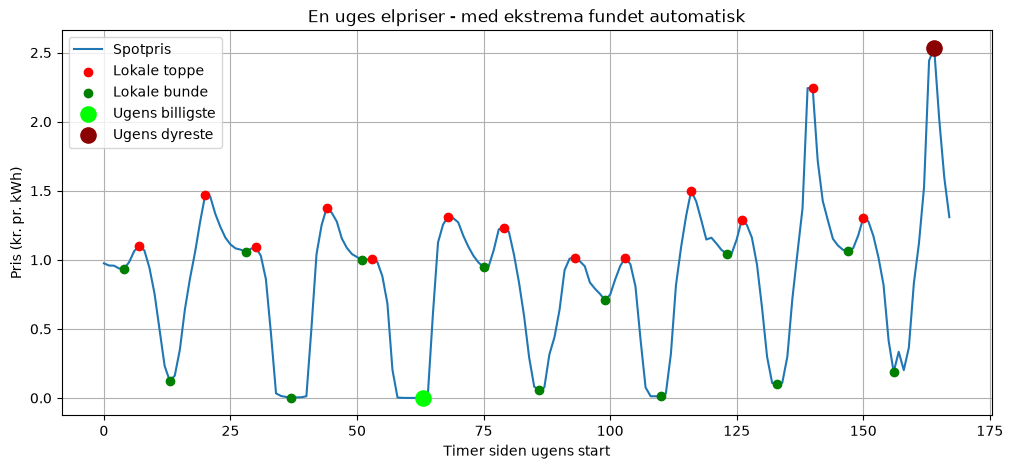

In [11]:
from scipy.signal import find_peaks

# Lokale toppe (dyre timer) og lokale bunde (billige timer)
dyre_timer, smid_vaek = find_peaks(ugepriser, distance=8)
billige_timer, smid_vaek = find_peaks(-ugepriser, distance=8)

# Ugens absolut billigste og dyreste time
billigst = np.argmin(ugepriser)
dyrest = np.argmax(ugepriser)

plt.figure(figsize=(12, 5))
plt.plot(ugetimer, ugepriser, label="Spotpris")
plt.scatter(dyre_timer, ugepriser[dyre_timer], color='red', label="Lokale toppe", zorder=5)
plt.scatter(billige_timer, ugepriser[billige_timer], color='green', label="Lokale bunde", zorder=5)
plt.scatter(billigst, ugepriser[billigst], color='lime', s=120, label="Ugens billigste", zorder=6)
plt.scatter(dyrest, ugepriser[dyrest], color='darkred', s=120, label="Ugens dyreste", zorder=6)
plt.title("En uges elpriser - med ekstrema fundet automatisk")
plt.xlabel("Timer siden ugens start")
plt.ylabel("Pris (kr. pr. kWh)")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
# Hvad er planlægning værd? En tørretumbler bruger ca. 2.5 kWh pr. tur
kwh_pr_tur = 2.5
pris_dum = kwh_pr_tur * ugepriser[dyrest]     # altid på det dyreste tidspunkt
pris_klog = kwh_pr_tur * ugepriser[billigst]  # altid på det billigste

print(f"Ugens dyreste time: {ugepriser[dyrest]:.2f} kr/kWh - ugens billigste: {ugepriser[billigst]:.2f} kr/kWh")
print(f"Én tumbling: {pris_dum:.2f} kr. på værste tidspunkt, {pris_klog:.2f} kr. på bedste")

# 3 ture om ugen, 52 uger om året - dette er et OPTIMISTISK loft, ikke en realistisk forventning:
# det kræver, at du rammer ugens billigste time hver eneste gang, hele året igennem
aarlig_besparelse = 3 * 52 * (pris_dum - pris_klog)
print(f"Et optimistisk overslag: op til {aarlig_besparelse:.0f} kr. om året, HVIS du altid rammer den billigste time - alene på tørretumbleren")

Ugens dyreste time: 2.53 kr/kWh - ugens billigste: -0.00 kr/kWh
Én tumbling: 6.33 kr. på værste tidspunkt, -0.00 kr. på bedste
Et optimistisk overslag: op til 988 kr. om året, HVIS du altid rammer den billigste time - alene på tørretumbleren


#### Drej på knapperne

* **Flere eller færre toppe**: I cellen med `find_peaks`: ret `distance=8` til `distance=3`, og kør cellen igen.
* **Dit eget apparat**: Ret `kwh_pr_tur = 2.5` til fx `40` (en elbil-opladning!), og kør cellen igen. Hvad er planlægning så værd om året?


# Kapitel 4 (efter lektion 4): Varme-miksen

Et hjem med både **elvarme** (varmepumpe) og **fjernvarme** skal dække et fast varmebehov - men hvad er den billigste fordeling? Marginalomkostningerne stiger, jo hårdere man presser hvert system (virkningsgraden falder), så omkostningerne er *kvadratiske* - og så er det her et Lagrange-problem, præcis som i lektion 4.

En varmepumpe leverer typisk ca. 3 kWh varme per kWh strøm, den bruger (COP = 3) - så modellen regner i kWh **varme** leveret fra hver kilde, ikke i kWh strøm forbrugt.

Modellen er stiliseret, men elprisen i den er dagens rigtige gennemsnitspris fra kapitel 1.

In [13]:
# Dagens gennemsnitlige elpris (fra kapitel 1) og en typisk fjernvarmepris
p_el = float(np.mean(elpriser))
p_fv = 0.85  # kr. pr. kWh, typisk fjernvarmetakst
varmebehov = 300  # kWh pr. måned i fyringssæsonen

print(f"Dagens gennemsnitlige elpris: {p_el:.2f} kr/kWh")

Dagens gennemsnitlige elpris: 1.05 kr/kWh


In [14]:
from sympy import symbols, diff, solve

x, y, lam = symbols('x y lam')  # x = kWh VARME fra elvarme (varmepumpe), y = kWh VARME fra fjernvarme
COP = 3  # en varmepumpe leverer typisk ca. 3 kWh varme per kWh strøm, den bruger

# Omkostninger: elvarmens pris betales på STRØMMEN varmepumpen trækker (x/COP), ikke på varmen selv.
# Plus et kvadratisk led for begge (faldende effektivitet ved høj last).
C = p_el * x / COP + 0.002 * x**2 + p_fv * y + 0.001 * y**2

# Betingelse: varmebehovet SKAL dækkes af de to kilder tilsammen: x + y = varmebehov
L = C - lam * (x + y - varmebehov)

# Kritisk punkt: alle partielle afledte = 0 (lektion 4)
loesning = solve([diff(L, x), diff(L, y), diff(L, lam)], (x, y, lam))
x_opt, y_opt, lam_opt = loesning[x], loesning[y], loesning[lam]

if x_opt < 0 or y_opt < 0:
    print("Med disse priser giver modellen en negativ mængde - i praksis ville man bruge 100% af den billige kilde.")
else:
    print(f"Billigste miks: {x_opt:.0f} kWh varme fra elvarme + {y_opt:.0f} kWh varme fra fjernvarme")
    print(f"Månedlig varmeudgift: {C.subs({x: x_opt, y: y_opt}):.0f} kr.")
    print(f"Lambda (skyggeprisen): {lam_opt:.2f} kr. - så meget koster én ekstra kWh varmebehov")

Billigste miks: 183 kWh varme fra elvarme + 117 kWh varme fra fjernvarme
Månedlig varmeudgift: 244 kr.
Lambda (skyggeprisen): 1.08 kr. - så meget koster én ekstra kWh varmebehov


#### Drej på knapperne

* **Januar**: Ret `varmebehov = 300` til `500` i cellen med priserne, og kør begge celler igen - hvordan flytter mikset sig?
* **Dyrere fjernvarme**: Ret `p_fv = 0.85` til `1.20`, og kør igen.
* **I morgen**: Kør hele notebooken igen en anden dag - løsningen følger elprisen helt automatisk. *Dét* er pointen med at bygge modeller i Python.


# Kapitel 5 (efter lektion 5): Fast eller variabel elaftale?

To typiske aftaler (tallene er illustrative - spotprisen er ægte):

* **Fastpris**: ingen abonnement, men 2,35 kr. pr. kWh - året rundt.
* **Variabel**: 49 kr. i abonnement pr. måned + spotprisen + 0,65 kr. i tillæg pr. kWh.

Hvornår er hvad billigst? Det er to lineære funktioner - og krydspunktet er et **lineært ligningssystem**, som vi løser præcis som i lektion 5.

Priserne her er leverandørens komponent af regningen - den fulde elregning har også nettarif, afgifter og moms oveni.

In [15]:
#@title Maskinrummet: henter den seneste måneds gennemsnitlige spotpris
_GEMT_AVG = 0.834

def hent_maanedens_gennemsnit():
    try:
        from datetime import date, timedelta
        slut = date.today()
        start = slut - timedelta(days=30)
        r = requests.get("https://api.energidataservice.dk/dataset/DayAheadPrices",
                         params={"start": str(start), "end": str(slut), "limit": 3000,
                                 "filter": json.dumps({"PriceArea": ["DK1"]})}, timeout=15)
        rec = r.json()["records"]
        avg = sum(x["DayAheadPriceDKK"] for x in rec) / len(rec) / 1000
        print(f"Seneste måneds gennemsnitlige spotpris: {avg:.2f} kr/kWh")
        return avg
    except Exception:
        print(f"(Kunne ikke hente live data - bruger gemt gennemsnit: {_GEMT_AVG} kr/kWh)")
        return _GEMT_AVG

spot_gennemsnit = hent_maanedens_gennemsnit()

(Kunne ikke hente live data - bruger gemt gennemsnit: 0.834 kr/kWh)


In [16]:
from sympy import Matrix
from sympy.solvers.solveset import linsolve

# Månedspris som funktion af forbrug f (kWh):
#   Fastpris:  pris = 2.35*f            ->  2.35*f - pris = 0
#   Variabel:  pris = 49 + a*f          ->  a*f - pris = -49
a = spot_gennemsnit + 0.65

f, pris = symbols('f pris')
kryds = linsolve(Matrix(([2.35, -1, 0], [a, -1, -49])), (f, pris))
print(f"Aftalerne koster det samme ved {list(kryds)[0][0]:.0f} kWh/md ({list(kryds)[0][1]:.0f} kr./md)")

# Samme svar med NumPy (lektion 5)
A_sys = np.array([[2.35, -1], [a, -1]])
b_sys = np.array([0, -49])
np.linalg.solve(A_sys, b_sys)

Aftalerne koster det samme ved 57 kWh/md (133 kr./md)


array([ 56.58198614, 132.96766744])

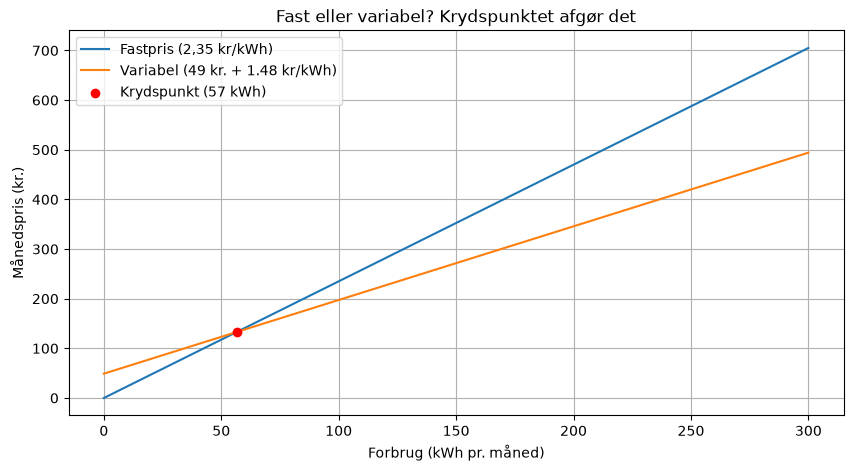

En typisk lejlighed bruger 125-175 kWh/md - aflæs selv, hvilken aftale der vinder lige nu


In [17]:
# Visualiser krydspunktet
forbrug = np.linspace(0, 300, 100)
plt.figure(figsize=(10, 5))
plt.plot(forbrug, 2.35 * forbrug, label="Fastpris (2,35 kr/kWh)")
plt.plot(forbrug, 49 + a * forbrug, label=f"Variabel (49 kr. + {a:.2f} kr/kWh)")

# Krydspunktet findes kun, hvis den variable pris pr. kWh (a) rent faktisk er LAVERE end fastprisen.
# Er a >= 2,35, er variabel dyrere ved ethvert forbrug (den har jo også et abonnement oveni) -
# så linjerne krydser aldrig for et positivt forbrug, og x_kryds ville blive meningsløst negativt.
if a >= 2.35:
    print(f"Med a = {a:.2f} kr/kWh er den variable aftale dyrere end fastprisen ved ethvert forbrug -")
    print("der er intet krydspunkt: fastprisaftalen vinder på alle forbrugsniveauer med disse priser.")
else:
    x_kryds = 49 / (2.35 - a)
    plt.scatter(x_kryds, 2.35 * x_kryds, color="red", zorder=5, label=f"Krydspunkt ({x_kryds:.0f} kWh)")

plt.title("Fast eller variabel? Krydspunktet afgør det")
plt.xlabel("Forbrug (kWh pr. måned)")
plt.ylabel("Månedspris (kr.)")
plt.legend()
plt.grid(True)
plt.show()

print("En typisk lejlighed bruger 125-175 kWh/md - aflæs selv, hvilken aftale der vinder lige nu")

#### Drej på knapperne

* **Uden abonnement**: Ret `49` til `0` i både udregnings-cellen og plot-cellen, og kør dem igen - hvor flytter krydspunktet hen?
* **Tilbage til 2022**: Skriv linjen `spot_gennemsnit = 2.10` som ny øverste linje i udregnings-cellen, og kør begge celler igen. Dengang så billedet helt anderledes ud.


# Kapitel 6 (efter lektion 6): Dit forbrug som vektor

Dit døgnforbrug er en **vektor**: 24 tal, ét pr. time. Dagens elpriser er også en vektor. Og din dagsregning? Den er **prikproduktet** af de to - præcis som i lektion 6.


In [18]:
# To døgnprofiler (kWh pr. time) - RÅ facon, normaliseres nedenfor til samme døgnforbrug
morgenmenneske_raa = np.array([0.1, 0.1, 0.1, 0.1, 0.1, 0.3, 0.8, 0.9, 0.6, 0.3, 0.2, 0.2,
                           0.2, 0.2, 0.2, 0.3, 0.5, 0.8, 0.9, 0.6, 0.4, 0.3, 0.2, 0.1])
natteravn_raa = np.array([0.4, 0.3, 0.2, 0.1, 0.1, 0.1, 0.1, 0.2, 0.3, 0.3, 0.3, 0.3,
                      0.3, 0.3, 0.3, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.8, 0.6])

# Skalér begge profiler til PRÆCIS samme døgnforbrug, så det kun er FORMEN (hvornår strømmen
# bruges), der adskiller de to husstande - ikke den samlede mængde
dagligt_forbrug = 8.0  # kWh
morgenmenneske = morgenmenneske_raa / np.sum(morgenmenneske_raa) * dagligt_forbrug
natteravn = natteravn_raa / np.sum(natteravn_raa) * dagligt_forbrug

print(f"Morgenmenneske: {np.sum(morgenmenneske):.1f} kWh/døgn - Natteravn: {np.sum(natteravn):.1f} kWh/døgn")

Morgenmenneske: 8.0 kWh/døgn - Natteravn: 8.0 kWh/døgn


In [19]:
# Dagsregningen = forbrugsvektor . prisvektor (prikproduktet fra lektion 6)
regning_morgen = morgenmenneske @ elpriser
regning_nat = natteravn @ elpriser

print(f"Morgenmenneskets dag: {regning_morgen:.2f} kr.")
print(f"Natteravnens dag: {regning_nat:.2f} kr.")
print(f"Forskel: {abs(regning_morgen - regning_nat):.2f} kr. - for PRÆCIS samme mængde strøm")

Morgenmenneskets dag: 9.31 kr.
Natteravnens dag: 9.69 kr.
Forskel: 0.38 kr. - for PRÆCIS samme mængde strøm


10% mindre forbrug: 8.38 kr. (før: 9.31 kr.)


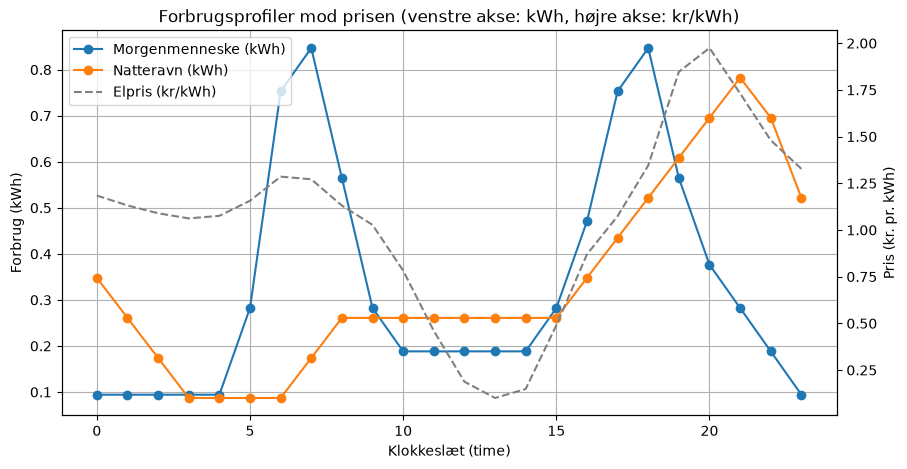

In [20]:
# Skalarmultiplikation: spar 10% overalt
spare_profil = 0.9 * morgenmenneske
print(f"10% mindre forbrug: {spare_profil @ elpriser:.2f} kr. (før: {regning_morgen:.2f} kr.)")

# Visualiser profilerne mod prisen - to Y-akser, for kWh og kr/kWh er ikke samme enhed
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(timer, morgenmenneske, 'o-', color='tab:blue', label="Morgenmenneske (kWh)")
ax1.plot(timer, natteravn, 'o-', color='tab:orange', label="Natteravn (kWh)")
ax1.set_xlabel("Klokkeslæt (time)")
ax1.set_ylabel("Forbrug (kWh)")

ax2 = ax1.twinx()
ax2.plot(timer, elpriser, '--', color='gray', label="Elpris (kr/kWh)")
ax2.set_ylabel("Pris (kr. pr. kWh)")

linjer1, navne1 = ax1.get_legend_handles_labels()
linjer2, navne2 = ax2.get_legend_handles_labels()
ax1.legend(linjer1 + linjer2, navne1 + navne2, loc="upper left")

plt.title("Forbrugsprofiler mod prisen (venstre akse: kWh, højre akse: kr/kWh)")
ax1.grid(True)
plt.show()

#### Drej på knapperne

* **Din egen profil**: Opret en ny celle (knappen `+ Kode`), kopiér linjerne med `morgenmenneske = np.array([...])` ind, ret navnet til `min_profil`, og justér de 24 tal, så de ligner din hverdag. Beregn så din dagsregning: `print(min_profil @ elpriser)`.
* **Flyt 1 kWh**: I `natteravn`-vektoren er tallet for kl. 21 det 22. tal i rækken. Gør det `0.5` mindre, gør tallet for kl. 3 (det 4. tal) `0.5` større, og kør cellerne igen. Hvad sparer natteravnen på at flytte forbruget?


# Kapitel 7 (efter lektion 7): Et helt år gennem én multiplikation

Nu skruer vi op. Vi henter **8.760 timepriser** - et helt års timedata (det seneste komplette år med timeopløsning, oktober 2024 til september 2025; siden da opgøres priserne pr. kvarter). Bemærk i øvrigt: prisen kan faktisk være *negativ*, når vindmøllerne producerer mere, end Danmark kan bruge.

Tre husstande, 365 dage, 24 timer: Med lektion 7's **matrixmultiplikation** beregner vi alle tre husstandes omkostninger for hver eneste dag i året - i én enkelt operation.


In [21]:
#@title Maskinrummet: henter et helt års timepriser (8760 tal)
_GEMTE_AARSPRISER = [0.024, 0.001, 0.0, 0.0, 0.001, 0.051, 0.25, 0.294, 0.308, 0.309, 0.288, 0.261, 0.261, 0.261, 0.261, 0.296, 0.325, 0.393, 0.406, 0.421, 0.367, 0.345, 0.322, 0.31, 0.433, 0.367, 0.374, 0.365, 0.363, 0.363, 0.596, 0.693, 0.914, 0.701, 0.485, 0.394, 0.431, 0.597, 0.585, 0.607, 0.608, 0.746, 0.873, 0.97, 0.853, 0.72, 0.696, 0.634, 0.502, 0.491, 0.486, 0.479, 0.477, 0.48, 0.488, 0.547, 0.572, 0.544, 0.517, 0.47, 0.351, 0.253, 0.292, 0.383, 0.493, 0.669, 0.821, 0.86, 0.808, 0.737, 0.678, 0.608, 0.551, 0.541, 0.538, 0.537, 0.54, 0.575, 0.768, 0.944, 1.055, 0.867, 0.747, 0.634, 0.56, 0.548, 0.566, 0.59, 0.67, 0.799, 0.984, 1.112, 0.923, 0.745, 0.745, 0.671, 0.694, 0.631, 0.607, 0.563, 0.565, 0.595, 0.643, 0.749, 0.825, 0.768, 0.615, 0.509, 0.384, 0.29, 0.324, 0.419, 0.544, 0.69, 1.03, 1.029, 0.8, 0.705, 0.634, 0.5, 0.485, 0.452, 0.441, 0.433, 0.424, 0.433, 0.432, 0.525, 0.491, 0.448, 0.263, 0.124, 0.08, 0.042, 0.016, 0.013, 0.396, 0.617, 0.792, 0.725, 0.544, 0.443, 0.437, 0.385, 0.258, 0.263, 0.248, 0.225, 0.261, 0.292, 0.335, 0.378, 0.414, 0.384, 0.372, 0.356, 0.341, 0.322, 0.358, 0.458, 0.662, 0.874, 1.405, 1.405, 0.909, 0.745, 0.685, 0.59, 0.539, 0.5, 0.477, 0.445, 0.445, 0.503, 0.641, 0.823, 0.792, 0.634, 0.599, 0.547, 0.496, 0.529, 0.565, 0.578, 0.694, 0.85, 1.074, 1.142, 0.853, 0.708, 0.646, 0.504, 0.462, 0.447, 0.429, 0.405, 0.427, 0.476, 0.647, 0.826, 0.828, 0.649, 0.538, 0.447, 0.446, 0.446, 0.504, 0.576, 0.708, 0.876, 0.914, 0.948, 0.828, 0.714, 0.709, 0.614, 0.456, 0.35, 0.282, 0.239, 0.221, 0.295, 0.463, 0.633, 0.6, 0.503, 0.388, 0.29, 0.163, 0.119, 0.149, 0.277, 0.277, 0.285, 0.294, 0.288, 0.275, 0.264, 0.224, 0.236, 0.259, 0.259, 0.262, 0.268, 0.268, 0.274, 0.308, 0.439, 0.594, 0.401, 0.368, 0.325, 0.316, 0.31, 0.299, 0.298, 0.299, 0.497, 0.939, 1.208, 0.895, 0.744, 0.734, 0.655, 0.672, 0.593, 0.564, 0.56, 0.537, 0.507, 0.534, 0.4, 0.378, 0.311, 0.263, 0.256, 0.185, 0.107, 0.174, 0.263, 0.219, 0.424, 0.362, 0.299, 0.289, 0.288, 0.26, 0.189, 0.0, -0.0, -0.001, -0.003, -0.004, -0.001, -0.0, 0.013, 0.134, 0.073, 0.037, 0.046, 0.048, 0.053, 0.059, 0.095, 0.118, 0.166, 0.267, 0.403, 0.295, 0.287, 0.299, 0.275, 0.277, 0.263, 0.262, 0.256, 0.293, 0.464, 0.737, 0.974, 1.142, 0.88, 0.753, 0.696, 0.643, 0.616, 0.553, 0.65, 0.789, 1.183, 1.865, 1.964, 1.179, 0.851, 0.744, 0.707, 0.681, 0.645, 0.659, 0.627, 0.603, 0.668, 0.855, 1.383, 1.318, 0.825, 0.692, 0.62, 0.585, 0.535, 0.566, 0.622, 0.664, 0.9, 1.021, 0.726, 0.569, 0.497, 0.445, 0.304, 0.174, 0.096, 0.04, 0.027, 0.024, 0.061, 0.301, 0.354, 0.406, 0.355, 0.199, 0.106, 0.031, 0.015, 0.03, 0.106, 0.246, 0.263, 0.277, 0.272, 0.267, 0.258, 0.242, 0.198, 0.127, 0.091, 0.078, 0.042, 0.075, 0.216, 0.262, 0.299, 0.307, 0.302, 0.287, 0.287, 0.291, 0.305, 0.323, 0.474, 0.691, 0.893, 1.292, 1.276, 0.877, 0.73, 0.664, 0.613, 0.604, 0.606, 0.617, 0.588, 0.606, 0.629, 0.738, 1.117, 1.166, 0.828, 0.714, 0.636, 0.619, 0.598, 0.606, 0.629, 0.771, 0.997, 1.352, 1.064, 0.77, 0.722, 0.696, 0.638, 0.649, 0.619, 0.596, 0.561, 0.566, 0.573, 0.597, 0.685, 0.669, 0.631, 0.588, 0.547, 0.493, 0.455, 0.476, 0.59, 0.732, 0.814, 1.013, 0.887, 0.722, 0.673, 0.625, 0.547, 0.403, 0.409, 0.407, 0.417, 0.444, 0.242, 0.24, 0.291, 0.36, 0.341, 0.048, 0.001, 0.0, -0.007, -0.015, 0.0, 0.038, 0.414, 0.318, 0.269, 0.253, 0.156, 0.091, 0.014, -0.001, -0.001, -0.001, -0.001, -0.0, 0.024, 0.033, 0.301, 0.292, 0.24, 0.215, 0.209, 0.188, 0.21, 0.169, 0.435, 0.67, 0.97, 1.582, 1.405, 0.958, 0.75, 0.729, 0.693, 0.667, 0.653, 0.639, 0.624, 0.619, 0.641, 0.732, 1.119, 1.215, 0.846, 0.737, 0.639, 0.247, 0.233, 0.226, 0.23, 0.263, 0.759, 1.044, 1.177, 0.85, 0.698, 0.714, 0.659, 0.603, 0.621, 0.612, 0.621, 0.64, 0.676, 0.781, 1.025, 1.206, 0.958, 0.776, 0.694, 0.601, 0.575, 0.562, 0.658, 0.696, 1.01, 1.429, 1.313, 0.833, 0.755, 0.768, 0.695, 0.647, 0.597, 0.582, 0.564, 0.532, 0.598, 0.748, 1.058, 1.233, 0.875, 0.76, 0.694, 0.626, 0.59, 0.608, 0.714, 0.81, 0.922, 1.034, 0.852, 0.721, 0.698, 0.67, 0.624, 0.615, 0.612, 0.594, 0.616, 0.63, 0.706, 0.813, 0.923, 1.123, 0.913, 0.807, 0.701, 0.605, 0.583, 0.615, 0.741, 0.881, 1.184, 1.696, 1.379, 0.924, 0.868, 0.85, 0.801, 0.86, 0.818, 0.798, 0.804, 0.789, 0.797, 0.85, 0.938, 0.94, 0.877, 0.756, 0.608, 0.51, 0.472, 0.482, 0.608, 0.751, 0.938, 1.126, 0.886, 0.72, 0.662, 0.653, 0.572, 0.688, 0.627, 0.6, 0.614, 0.593, 0.588, 0.635, 0.666, 0.657, 0.629, 0.496, 0.408, 0.317, 0.298, 0.298, 0.48, 0.753, 0.879, 1.107, 1.087, 0.974, 0.881, 0.831, 0.82, 0.651, 0.713, 0.667, 0.628, 0.592, 0.596, 0.702, 0.738, 0.97, 0.95, 0.867, 0.728, 0.734, 0.708, 0.756, 0.85, 0.906, 0.927, 1.053, 1.11, 1.09, 0.927, 0.862, 0.82, 0.764, 0.756, 0.746, 0.737, 0.732, 0.746, 0.844, 0.95, 1.176, 1.129, 0.967, 0.9, 0.843, 0.786, 0.878, 1.014, 1.285, 1.587, 2.132, 1.92, 1.52, 1.049, 0.916, 0.867, 0.769, 0.744, 0.735, 0.646, 0.501, 0.478, 0.495, 0.543, 0.743, 0.773, 0.729, 0.469, 0.441, 0.415, 0.389, 0.633, 0.751, 1.062, 1.366, 1.439, 1.189, 0.817, 0.773, 0.81, 0.745, 0.785, 0.735, 0.721, 0.707, 0.658, 0.636, 0.656, 0.739, 0.646, 0.301, 0.155, 0.11, 0.093, 0.119, 0.118, 0.116, 0.116, 0.143, 0.125, 0.109, 0.093, 0.066, 0.053, 0.042, 0.024, 0.016, 0.013, 0.012, 0.011, 0.013, 0.024, 0.03, 0.033, 0.025, 0.024, 0.024, 0.024, 0.024, 0.024, 0.025, 0.077, 0.103, 0.149, 0.098, 0.109, 0.114, 0.149, 0.183, 0.462, 0.596, 0.662, 0.641, 0.648, 0.677, 0.72, 0.746, 0.754, 0.818, 0.68, 0.704, 0.661, 0.682, 0.771, 0.912, 1.026, 1.182, 1.118, 1.006, 0.916, 0.83, 0.792, 0.75, 0.755, 0.718, 0.661, 0.634, 0.57, 0.477, 0.417, 0.341, 0.298, 0.29, 0.25, 0.238, 0.235, 0.248, 0.437, 0.511, 0.667, 0.721, 0.719, 0.705, 0.657, 0.647, 0.665, 0.689, 0.686, 0.671, 0.672, 0.67, 0.677, 0.735, 0.931, 1.081, 1.024, 0.896, 0.777, 0.698, 0.71, 0.734, 0.746, 0.96, 1.323, 2.012, 1.772, 1.206, 0.917, 0.821, 0.783, 0.691, 0.624, 0.701, 0.676, 0.681, 0.701, 0.717, 0.79, 1.022, 1.016, 0.882, 0.79, 0.711, 0.708, 0.74, 0.817, 1.147, 2.4, 3.527, 3.214, 2.389, 1.266, 0.969, 0.878, 0.76, 0.745, 0.739, 0.712, 0.715, 0.717, 0.693, 0.902, 1.609, 1.447, 1.059, 0.983, 0.911, 0.909, 0.926, 1.021, 1.422, 2.244, 4.102, 2.499, 1.838, 1.199, 0.962, 0.843, 0.714, 0.671, 0.662, 0.653, 0.649, 0.508, 0.68, 0.76, 1.29, 1.424, 1.14, 1.11, 1.005, 1.007, 0.991, 1.044, 1.334, 1.811, 2.768, 2.071, 1.281, 0.965, 0.849, 0.833, 0.745, 0.522, 0.49, 0.434, 0.43, 0.325, 0.521, 0.754, 0.951, 0.991, 0.943, 0.875, 0.822, 0.787, 0.715, 0.713, 0.715, 0.963, 0.959, 0.753, 0.577, 0.299, 0.289, 0.289, 0.281, 0.784, 0.745, 0.731, 0.721, 0.734, 0.751, 0.778, 0.819, 0.851, 0.855, 0.82, 0.793, 0.797, 0.805, 0.822, 0.906, 1.023, 1.096, 1.102, 1.043, 0.957, 0.88, 0.854, 0.821, 0.783, 0.763, 0.761, 0.752, 0.752, 0.76, 0.748, 0.764, 0.786, 0.828, 0.84, 0.821, 0.827, 0.81, 0.838, 0.941, 0.999, 1.109, 1.089, 1.034, 0.934, 0.86, 0.828, 0.806, 0.818, 0.773, 0.746, 0.73, 0.727, 0.775, 0.863, 0.957, 1.007, 0.991, 0.958, 0.926, 0.894, 0.962, 0.973, 1.037, 1.051, 1.142, 1.097, 0.997, 0.909, 0.842, 0.832, 0.786, 0.823, 0.78, 0.766, 0.775, 0.802, 0.88, 1.101, 1.383, 1.504, 1.647, 1.419, 1.276, 1.205, 1.167, 1.3, 1.631, 2.034, 2.371, 1.68, 1.278, 1.112, 0.984, 0.934, 0.862, 0.874, 0.833, 0.804, 0.801, 0.805, 0.853, 0.972, 1.229, 1.682, 1.596, 1.416, 1.266, 1.165, 1.15, 1.144, 1.209, 1.265, 1.324, 1.297, 1.113, 0.693, 0.549, 0.376, 0.299, 0.384, 0.361, 0.365, 0.369, 0.319, 0.379, 0.613, 0.753, 0.87, 0.837, 0.81, 0.833, 0.851, 0.95, 1.0, 1.061, 1.1, 1.163, 1.149, 1.106, 1.034, 0.966, 0.917, 0.839, 0.774, 0.762, 0.747, 0.746, 0.667, 0.667, 0.703, 0.953, 1.097, 1.025, 0.998, 0.799, 0.762, 0.718, 0.709, 0.709, 0.71, 0.743, 0.573, 0.298, 0.293, 0.268, 0.259, 0.24, 0.142, 0.041, 0.036, 0.035, 0.036, 0.036, 0.038, 0.125, 0.166, 0.216, 0.261, 0.179, 0.163, 0.149, 0.18, 0.259, 0.291, 0.351, 0.337, 0.297, 0.261, 0.286, 0.221, 0.148, 0.123, 0.129, 0.224, 0.204, 0.162, 0.186, 0.226, 0.231, 0.2, 0.205, 0.145, 0.111, 0.112, 0.111, 0.236, 0.241, 0.283, 0.293, 0.288, 0.28, 0.268, 0.26, 0.246, 0.214, 0.407, 0.401, 0.318, 0.315, 0.319, 0.268, 0.442, 0.702, 0.864, 0.753, 0.63, 0.596, 0.559, 0.507, 0.592, 0.785, 0.907, 1.097, 1.207, 1.132, 0.952, 0.877, 0.873, 0.809, 0.799, 0.756, 0.713, 0.684, 0.711, 0.728, 0.867, 0.985, 1.158, 1.177, 1.166, 1.14, 1.106, 1.076, 1.046, 0.963, 0.991, 1.046, 1.004, 0.939, 0.874, 0.816, 0.785, 0.67, 0.747, 0.686, 0.646, 0.608, 0.611, 0.696, 0.802, 0.998, 1.066, 1.044, 0.898, 0.804, 0.726, 0.726, 0.792, 0.953, 0.998, 1.059, 1.064, 1.046, 1.014, 0.918, 0.868, 0.772, 0.701, 0.674, 0.647, 0.628, 0.628, 0.69, 0.799, 0.906, 0.992, 1.007, 0.95, 0.861, 0.847, 0.901, 1.056, 1.155, 1.305, 1.359, 1.203, 1.149, 0.98, 0.918, 0.917, 0.802, 0.866, 0.792, 0.73, 0.681, 0.661, 0.687, 0.873, 1.009, 1.115, 1.076, 1.024, 0.896, 0.789, 0.71, 0.717, 0.792, 0.829, 0.958, 1.002, 0.961, 0.792, 0.742, 0.65, 0.571, 0.458, 0.392, 0.378, 0.357, 0.367, 0.368, 0.377, 0.501, 0.651, 0.639, 0.586, 0.548, 0.531, 0.566, 0.639, 0.75, 0.642, 0.71, 0.632, 0.53, 0.444, 0.358, 0.292, 0.138, 0.012, 0.013, 0.002, 0.003, 0.002, 0.002, 0.003, 0.004, 0.013, 0.028, 0.017, 0.02, 0.017, 0.02, 0.023, 0.049, 0.104, 0.116, 0.121, 0.09, 0.055, 0.034, 0.024, 0.0, -0.009, -0.012, -0.011, -0.014, -0.011, -0.002, 0.0, 0.406, 0.452, 0.302, 0.317, 0.309, 0.298, 0.364, 0.347, 0.301, 0.313, 0.353, 0.347, 0.305, 0.29, 0.228, 0.197, 0.298, 0.12, 0.138, 0.15, 0.137, 0.139, 0.147, 0.284, 0.295, 0.306, 0.298, 0.3, 0.298, 0.298, 0.3, 0.306, 0.352, 0.355, 0.356, 0.355, 0.311, 0.353, 0.355, 0.318, 0.383, 0.781, 0.793, 0.82, 0.77, 0.752, 0.836, 0.817, 1.105, 1.272, 1.184, 1.142, 1.119, 1.086, 1.048, 0.97, 0.982, 0.878, 0.83, 0.838, 0.76, 0.583, 0.536, 0.5, 0.364, 0.367, 0.307, 0.246, 0.239, 0.236, 0.39, 0.472, 0.653, 0.761, 0.714, 0.663, 0.647, 0.627, 0.625, 0.71, 0.795, 0.989, 1.114, 1.18, 1.148, 1.074, 0.988, 0.911, 0.84, 0.823, 0.798, 0.772, 0.767, 0.785, 0.86, 1.014, 1.222, 1.294, 1.174, 1.032, 0.895, 0.821, 0.852, 0.815, 0.915, 0.915, 1.077, 1.059, 0.976, 0.894, 0.836, 0.848, 0.77, 0.597, 0.452, 0.386, 0.294, 0.289, 0.277, 0.283, 0.299, 0.306, 0.313, 0.312, 0.317, 0.314, 0.41, 0.666, 0.742, 0.858, 1.021, 1.014, 0.969, 0.868, 0.837, 0.856, 0.796, 0.71, 0.671, 0.657, 0.639, 0.629, 0.597, 0.621, 0.665, 0.74, 0.706, 0.666, 0.614, 0.636, 0.62, 0.676, 0.767, 0.876, 0.82, 0.757, 0.623, 0.502, 0.439, 0.374, 0.339, 0.166, 0.202, 0.235, 0.235, 0.237, 0.285, 0.399, 0.423, 0.496, 0.487, 0.485, 0.485, 0.501, 0.523, 0.679, 0.808, 0.997, 1.097, 1.103, 1.029, 0.861, 0.746, 0.711, 0.662, 0.712, 0.678, 0.656, 0.647, 0.708, 0.713, 0.895, 1.059, 1.109, 0.961, 0.754, 0.708, 0.708, 0.71, 1.076, 1.223, 1.486, 1.56, 1.476, 1.416, 1.256, 1.142, 1.06, 0.976, 0.902, 0.87, 0.841, 0.821, 0.833, 0.892, 1.048, 1.527, 2.005, 1.82, 1.583, 1.484, 1.434, 1.437, 1.548, 1.699, 1.877, 2.146, 1.717, 1.447, 1.185, 0.992, 0.895, 0.828, 0.856, 0.789, 0.747, 0.65, 0.574, 0.579, 0.681, 0.858, 0.955, 0.745, 0.685, 0.598, 0.562, 0.529, 0.469, 0.461, 0.406, 0.45, 0.4, 0.333, 0.304, 0.347, 0.312, 0.322, 0.079, 0.034, 0.029, 0.017, 0.022, 0.077, 0.468, 0.691, 0.822, 0.822, 0.776, 0.734, 0.685, 0.751, 0.813, 0.872, 0.981, 1.066, 1.127, 1.063, 0.97, 0.891, 0.903, 0.762, 0.646, 0.554, 0.507, 0.465, 0.366, 0.279, 0.285, 0.309, 0.404, 0.441, 0.401, 0.383, 0.404, 0.406, 0.428, 0.441, 0.455, 0.47, 0.463, 0.515, 0.559, 0.569, 0.552, 0.513, 0.325, 0.325, 0.379, 0.309, 0.303, 0.298, 0.305, 0.329, 0.341, 0.5, 0.663, 0.775, 0.642, 0.72, 0.635, 0.593, 0.621, 0.618, 0.584, 0.483, 0.432, 0.408, 0.317, 0.304, 0.32, 0.337, 0.261, 0.255, 0.243, 0.285, 0.319, 0.515, 0.608, 0.498, 0.501, 0.511, 0.521, 0.589, 0.691, 0.841, 0.859, 0.887, 0.872, 0.911, 0.844, 0.753, 0.734, 0.689, 0.576, 0.634, 0.645, 0.624, 0.65, 0.664, 0.836, 1.008, 1.266, 1.358, 1.378, 1.391, 1.347, 1.423, 1.413, 1.474, 1.485, 1.487, 1.35, 1.344, 1.242, 1.127, 1.029, 0.905, 0.865, 0.807, 0.8, 0.792, 0.811, 0.935, 1.219, 1.861, 2.656, 2.722, 2.525, 2.568, 2.491, 2.485, 2.701, 2.812, 3.266, 3.243, 2.684, 2.545, 1.542, 1.277, 1.119, 1.014, 0.912, 0.86, 0.82, 0.801, 0.839, 0.922, 1.314, 4.474, 4.889, 4.823, 4.056, 3.47, 3.02, 3.097, 3.657, 4.985, 6.108, 6.982, 5.028, 4.109, 2.205, 1.263, 1.119, 1.005, 0.97, 0.917, 0.887, 0.857, 0.862, 0.938, 1.167, 1.4, 1.887, 1.833, 1.554, 1.301, 1.238, 1.231, 1.376, 1.647, 1.865, 2.12, 1.939, 1.683, 1.305, 1.091, 1.008, 0.869, 0.872, 0.83, 0.806, 0.738, 0.697, 0.657, 0.518, 0.582, 0.662, 0.554, 0.3, 0.277, 0.28, 0.273, 0.265, 0.262, 0.274, 0.279, 0.25, 0.262, 0.232, 0.194, 0.221, 0.22, 0.336, 0.263, 0.232, 0.233, 0.252, 0.27, 0.272, 0.337, 0.37, 0.317, 0.301, 0.292, 0.291, 0.286, 0.273, 0.263, 0.256, 0.234, 0.194, 0.167, 0.138, 0.104, 0.075, 0.017, 0.001, 0.001, 0.0, 0.001, 0.0, 0.013, 0.058, 0.22, 0.257, 0.237, 0.23, 0.224, 0.219, 0.217, 0.213, 0.246, 0.241, 0.231, 0.242, 0.221, 0.19, 0.167, 0.125, 0.124, 0.106, 0.15, 0.147, 0.154, 0.127, 0.124, 0.262, 0.334, 0.384, 0.421, 0.395, 0.382, 0.453, 0.476, 0.641, 0.801, 0.839, 0.95, 0.907, 0.806, 0.735, 0.715, 0.6, 0.453, 0.168, 0.228, 0.203, 0.122, 0.109, 0.067, 0.045, 0.291, 0.371, 0.323, 0.25, 0.244, 0.237, 0.234, 0.23, 0.245, 0.212, 0.219, 0.147, 0.129, 0.119, 0.133, 0.154, 0.16, 0.084, 0.099, 0.041, 0.014, 0.002, 0.015, 0.064, 0.403, 0.496, 0.503, 0.485, 0.428, 0.277, 0.233, 0.228, 0.231, 0.234, 0.23, 0.16, 0.059, 0.048, 0.052, 0.049, 0.081, 0.083, 0.134, 0.122, 0.13, 0.103, 0.067, 0.04, 0.203, 0.151, 0.225, 0.233, 0.238, 0.251, 0.25, 0.262, 0.33, 0.537, 0.656, 0.583, 0.367, 0.25, 0.231, 0.185, 0.149, 0.087, 0.167, 0.161, 0.145, 0.135, 0.15, 0.149, 0.158, 0.171, 0.219, 0.234, 0.231, 0.232, 0.223, 0.193, 0.204, 0.219, 0.218, 0.209, 0.155, 0.114, 0.039, 0.032, 0.03, 0.014, 0.011, 0.002, -0.001, -0.006, -0.0, -0.0, 0.017, 0.045, 0.154, 0.15, 0.172, 0.158, 0.16, 0.209, 0.312, 0.35, 0.488, 0.453, 0.434, 0.35, 0.273, 0.27, 0.183, 0.218, 0.15, 0.107, 0.068, 0.073, 0.11, 0.13, 0.388, 0.443, 0.445, 0.393, 0.388, 0.404, 0.409, 0.459, 0.55, 0.616, 0.733, 0.759, 0.727, 0.691, 0.808, 0.789, 0.723, 0.642, 0.618, 0.611, 0.582, 0.588, 0.601, 0.635, 0.752, 0.858, 0.902, 0.895, 0.881, 0.876, 0.861, 0.88, 0.891, 0.897, 0.88, 0.828, 0.776, 0.765, 0.706, 0.739, 0.658, 0.682, 0.645, 0.635, 0.512, 0.461, 0.468, 0.467, 0.634, 0.673, 0.74, 0.698, 0.691, 0.704, 0.679, 0.74, 0.841, 0.871, 0.899, 0.889, 0.88, 0.883, 0.843, 0.851, 0.778, 0.762, 0.709, 0.706, 0.669, 0.678, 0.71, 0.739, 0.84, 0.889, 0.882, 0.845, 0.791, 0.804, 0.775, 0.818, 0.901, 0.967, 1.029, 1.03, 1.013, 0.963, 0.902, 0.921, 0.873, 0.797, 0.757, 0.754, 0.744, 0.743, 0.792, 0.863, 0.927, 0.984, 0.971, 0.896, 0.805, 0.804, 0.805, 0.908, 1.018, 1.091, 1.133, 1.182, 1.093, 0.993, 0.936, 0.946, 0.851, 0.943, 0.87, 0.822, 0.79, 0.768, 0.788, 0.819, 0.927, 0.955, 0.957, 0.916, 0.846, 0.813, 0.821, 0.879, 1.006, 1.039, 1.125, 1.101, 1.048, 0.964, 0.939, 0.905, 0.857, 0.95, 0.851, 0.803, 0.759, 0.729, 0.736, 0.501, 0.429, 0.401, 0.305, 0.19, 0.179, 0.218, 0.212, 0.184, 0.184, 0.205, 0.21, 0.186, 0.181, 0.176, 0.173, 0.149, 0.091, 0.027, 0.1, 0.1, 0.124, 0.146, 0.13, 0.191, 0.255, 0.278, 0.271, 0.287, 0.286, 0.271, 0.258, 0.269, 0.279, 0.296, 0.292, 0.275, 0.246, 0.235, 0.234, 0.22, 0.266, 0.377, 0.342, 0.421, 0.26, 0.23, 0.225, 0.298, 0.387, 0.585, 0.623, 0.357, 0.317, 0.277, 0.271, 0.149, 0.127, 0.139, 0.156, 0.194, 0.187, 0.142, 0.117, 0.068, 0.004, 0.016, 0.012, 0.012, 0.008, 0.004, 0.0, 0.006, 0.006, 0.014, 0.016, 0.026, 0.028, 0.028, 0.028, 0.04, 0.092, 0.147, 0.165, 0.13, 0.076, 0.06, 0.05, 0.075, 0.052, 0.021, 0.02, 0.027, 0.052, 0.095, 0.224, 0.501, 0.737, 0.906, 0.949, 0.929, 0.832, 0.749, 0.784, 0.829, 0.941, 1.009, 1.117, 1.083, 0.801, 0.765, 0.581, 0.49, 0.371, 0.318, 0.284, 0.263, 0.249, 0.214, 0.233, 0.287, 0.389, 0.599, 0.559, 0.563, 0.465, 0.402, 0.391, 0.4, 0.54, 0.748, 0.786, 0.806, 0.749, 0.61, 0.6, 0.501, 0.559, 0.675, 0.674, 0.673, 0.683, 0.716, 0.762, 0.826, 0.895, 0.958, 0.975, 0.972, 0.957, 0.97, 0.969, 1.018, 1.035, 1.059, 1.128, 1.073, 1.029, 0.966, 0.916, 0.882, 0.817, 0.849, 0.748, 0.698, 0.7, 0.667, 0.623, 0.626, 0.616, 0.627, 0.657, 0.619, 0.662, 0.609, 0.578, 0.507, 0.378, 0.372, 0.473, 0.461, 0.378, 0.275, 0.274, 0.259, 0.21, 0.205, 0.144, 0.085, 0.069, 0.075, 0.11, 0.178, 0.237, 0.295, 0.269, 0.259, 0.245, 0.233, 0.213, 0.191, 0.196, 0.2, 0.236, 0.236, 0.209, 0.185, 0.103, 0.152, 0.075, 0.101, 0.065, 0.066, 0.037, 0.038, 0.043, 0.334, 0.284, 0.277, 0.261, 0.256, 0.258, 0.249, 0.248, 0.248, 0.248, 0.261, 0.287, 0.261, 0.247, 0.188, 0.149, 0.169, 0.277, 0.153, 0.174, 0.179, 0.172, 0.197, 0.212, 0.231, 0.347, 0.44, 0.501, 0.532, 0.552, 0.542, 0.582, 0.634, 0.786, 0.936, 1.14, 1.113, 1.084, 0.882, 0.751, 0.686, 0.682, 0.757, 0.746, 0.737, 0.71, 0.733, 0.766, 0.996, 1.11, 1.23, 1.165, 1.102, 1.046, 0.956, 0.904, 0.925, 0.954, 0.95, 0.986, 1.015, 0.966, 0.89, 0.783, 0.754, 0.658, 0.633, 0.599, 0.532, 0.515, 0.521, 0.626, 0.739, 0.925, 1.041, 1.022, 0.922, 0.848, 0.802, 0.783, 0.821, 0.96, 1.006, 1.064, 1.075, 1.052, 0.961, 0.818, 0.868, 0.82, 0.741, 0.758, 0.704, 0.667, 0.569, 0.501, 0.576, 0.706, 0.803, 0.77, 0.755, 0.679, 0.679, 0.679, 0.666, 0.765, 0.837, 0.894, 0.913, 0.857, 0.807, 0.782, 0.769, 0.789, 0.624, 0.625, 0.647, 0.628, 0.634, 0.625, 0.641, 0.759, 0.855, 0.896, 0.879, 0.788, 0.768, 0.743, 0.781, 0.886, 0.992, 1.052, 1.094, 1.072, 1.006, 0.951, 0.904, 0.857, 0.838, 0.784, 0.779, 0.749, 0.675, 0.445, 0.635, 0.91, 1.14, 0.859, 0.686, 0.503, 0.427, 0.419, 0.467, 0.423, 0.482, 0.501, 0.374, 0.301, 0.184, 0.171, 0.157, 0.133, 0.275, 0.298, 0.31, 0.315, 0.3, 0.345, 0.376, 0.45, 0.511, 0.47, 0.411, 0.419, 0.36, 0.389, 0.451, 0.425, 0.518, 0.551, 0.521, 0.463, 0.44, 0.443, 0.439, 0.514, 0.463, 0.472, 0.484, 0.579, 0.786, 0.857, 0.996, 1.431, 2.292, 2.35, 2.321, 2.274, 2.321, 2.308, 2.133, 1.958, 1.943, 2.203, 2.015, 1.666, 1.278, 0.965, 0.996, 0.661, 0.931, 0.827, 0.717, 0.437, 0.435, 0.501, 0.766, 0.939, 1.12, 1.059, 0.888, 0.552, 0.526, 0.507, 0.526, 0.648, 1.008, 1.201, 1.19, 0.66, 0.571, 0.519, 0.514, 0.474, 0.415, 0.431, 0.451, 0.451, 0.478, 0.522, 0.708, 0.81, 0.791, 0.721, 0.58, 0.518, 0.484, 0.476, 0.506, 0.556, 0.687, 1.25, 1.306, 1.251, 1.093, 1.021, 0.889, 0.772, 0.932, 0.903, 0.903, 0.887, 0.868, 0.894, 0.892, 0.784, 1.034, 1.075, 0.979, 0.907, 0.887, 0.858, 0.89, 0.995, 1.117, 1.228, 1.25, 1.252, 1.165, 1.07, 1.018, 0.965, 0.968, 0.927, 0.918, 0.905, 0.897, 0.895, 0.907, 0.92, 0.922, 0.934, 0.934, 0.907, 0.837, 0.802, 0.872, 0.942, 1.046, 1.117, 1.187, 1.168, 1.112, 1.039, 0.977, 0.917, 0.912, 0.891, 0.87, 0.854, 0.861, 0.952, 1.206, 2.063, 3.223, 2.176, 1.763, 1.399, 1.313, 1.279, 1.438, 2.068, 3.0, 4.353, 3.531, 2.205, 1.641, 1.268, 1.138, 1.029, 0.951, 0.908, 0.87, 0.85, 0.832, 0.795, 0.798, 1.234, 1.563, 1.569, 1.478, 1.205, 1.1, 1.066, 1.12, 1.294, 1.51, 2.108, 1.82, 1.492, 1.304, 1.158, 1.034, 0.818, 0.798, 0.758, 0.784, 0.775, 0.7, 0.802, 0.963, 1.459, 1.78, 1.488, 1.336, 1.29, 1.231, 1.268, 1.343, 1.46, 1.485, 1.559, 1.346, 1.247, 1.004, 0.953, 0.956, 0.844, 0.842, 0.812, 0.788, 0.746, 0.728, 0.746, 0.794, 1.019, 1.187, 1.16, 0.977, 0.866, 0.707, 0.623, 0.54, 0.504, 0.624, 0.68, 0.635, 0.581, 0.486, 0.428, 0.417, 0.332, 0.278, 0.298, 0.31, 0.282, 0.269, 0.275, 0.304, 0.524, 0.597, 0.444, 0.351, 0.312, 0.277, 0.187, 0.173, 0.174, 0.149, 0.201, 0.214, 0.154, 0.157, 0.149, 0.098, 0.075, 0.126, 0.158, 0.148, 0.203, 0.183, 0.158, 0.222, 0.352, 0.447, 0.497, 0.591, 0.539, 0.611, 0.612, 0.635, 0.773, 0.926, 1.034, 1.098, 1.077, 0.976, 0.946, 0.929, 0.858, 0.942, 0.864, 0.831, 0.797, 0.787, 0.769, 0.742, 0.79, 0.809, 0.884, 0.787, 0.765, 0.722, 0.672, 0.69, 0.833, 0.94, 0.991, 0.818, 0.616, 0.519, 0.443, 0.323, 0.178, 0.292, 0.263, 0.197, 0.105, 0.075, 0.161, 0.249, 0.383, 0.451, 0.288, 0.304, 0.276, 0.255, 0.268, 0.298, 0.352, 0.373, 0.403, 0.405, 0.375, 0.338, 0.302, 0.288, 0.281, 0.29, 0.284, 0.266, 0.284, 0.305, 0.318, 0.429, 0.79, 0.887, 0.858, 0.842, 0.812, 0.799, 0.813, 0.841, 0.934, 0.972, 1.043, 0.899, 0.822, 0.637, 0.538, 0.463, 0.379, 0.655, 0.622, 0.583, 0.565, 0.566, 0.601, 0.693, 1.055, 1.064, 0.974, 0.784, 0.666, 0.634, 0.638, 0.654, 0.767, 0.987, 1.116, 1.12, 1.035, 0.815, 0.768, 0.799, 0.741, 0.635, 0.626, 0.597, 0.569, 0.57, 0.705, 0.84, 0.971, 1.074, 1.032, 0.933, 0.801, 0.804, 0.818, 0.921, 1.05, 1.09, 1.29, 1.242, 1.135, 1.05, 0.941, 0.89, 0.82, 0.805, 0.708, 0.708, 0.699, 0.608, 0.555, 0.776, 1.149, 1.222, 1.155, 0.971, 0.942, 0.896, 0.904, 0.894, 1.118, 1.256, 1.382, 1.377, 1.336, 1.214, 1.139, 1.077, 0.981, 1.022, 0.962, 0.927, 0.889, 0.824, 0.742, 0.869, 0.936, 1.102, 1.063, 0.958, 0.896, 0.823, 0.772, 0.848, 0.956, 1.135, 1.241, 1.25, 1.216, 1.164, 1.084, 1.058, 0.983, 0.994, 0.947, 0.918, 0.9, 0.913, 0.921, 0.956, 1.014, 1.025, 1.027, 0.97, 0.965, 0.912, 0.835, 0.869, 0.955, 1.128, 1.224, 1.287, 1.298, 1.232, 1.089, 0.919, 0.908, 0.935, 0.945, 0.931, 0.896, 0.828, 0.872, 1.188, 1.551, 1.815, 1.328, 1.119, 0.941, 0.875, 0.86, 0.927, 1.08, 1.274, 1.612, 1.498, 1.498, 1.247, 1.071, 0.912, 0.698, 0.885, 0.9, 0.823, 0.727, 0.58, 0.601, 0.795, 1.158, 1.472, 1.124, 1.005, 0.842, 0.726, 0.642, 0.584, 0.603, 0.712, 0.745, 0.738, 0.642, 0.563, 0.507, 0.485, 0.394, 0.444, 0.436, 0.438, 0.436, 0.459, 0.566, 0.649, 0.737, 0.802, 0.749, 0.656, 0.512, 0.508, 0.51, 0.617, 0.7, 0.81, 0.973, 1.033, 1.027, 0.913, 0.864, 0.796, 0.681, 0.816, 0.87, 0.899, 0.915, 0.86, 0.912, 0.894, 1.296, 1.589, 1.325, 1.181, 1.009, 0.883, 0.879, 0.828, 0.97, 1.044, 1.269, 1.272, 1.213, 1.05, 0.978, 0.91, 0.858, 0.846, 0.81, 0.812, 0.783, 0.654, 0.67, 0.824, 1.055, 1.223, 1.119, 0.963, 0.746, 0.665, 0.665, 0.663, 0.645, 0.73, 0.8, 0.811, 0.684, 0.559, 0.514, 0.473, 0.474, 0.423, 0.42, 0.44, 0.433, 0.44, 0.44, 0.455, 0.47, 0.519, 0.493, 0.466, 0.432, 0.434, 0.461, 0.534, 0.652, 0.67, 0.837, 0.844, 0.806, 0.799, 0.844, 0.954, 0.84, 1.007, 0.97, 0.855, 0.89, 0.865, 0.844, 0.86, 0.892, 0.91, 0.896, 0.828, 0.775, 0.675, 0.649, 0.685, 0.783, 0.872, 0.97, 0.895, 0.787, 0.678, 0.644, 0.607, 0.537, 0.515, 0.486, 0.469, 0.476, 0.474, 0.501, 0.64, 0.861, 0.975, 0.903, 0.762, 0.621, 0.57, 0.565, 0.59, 0.585, 0.631, 0.654, 0.676, 0.583, 0.519, 0.502, 0.486, 0.477, 0.403, 0.417, 0.416, 0.419, 0.419, 0.447, 0.521, 0.609, 0.741, 0.642, 0.545, 0.531, 0.527, 0.541, 0.556, 0.581, 0.609, 0.7, 0.79, 0.671, 0.604, 0.595, 0.601, 0.573, 0.595, 0.587, 0.582, 0.58, 0.592, 0.605, 0.806, 1.112, 1.226, 1.179, 0.977, 0.849, 0.83, 0.875, 0.964, 1.026, 1.253, 1.365, 1.445, 1.426, 1.267, 1.134, 1.089, 0.876, 1.047, 1.027, 1.05, 1.019, 0.895, 0.891, 1.057, 1.416, 1.639, 1.601, 1.481, 1.335, 1.245, 1.06, 1.046, 1.07, 1.134, 1.477, 1.459, 1.336, 1.171, 1.088, 1.02, 0.934, 1.026, 0.991, 0.958, 0.952, 0.949, 1.041, 1.2, 1.694, 1.981, 1.605, 1.35, 1.216, 1.118, 1.108, 1.162, 1.306, 1.492, 2.23, 2.186, 1.683, 1.369, 1.222, 1.141, 1.044, 1.009, 0.972, 0.895, 0.882, 0.884, 0.897, 0.966, 1.082, 1.124, 1.022, 0.929, 0.883, 0.838, 0.821, 0.866, 0.961, 1.044, 1.183, 1.272, 1.223, 1.099, 0.955, 0.982, 0.929, 1.0, 0.961, 0.922, 0.894, 0.892, 0.896, 0.894, 0.951, 0.967, 0.973, 0.953, 0.925, 0.93, 0.886, 0.903, 0.966, 1.027, 1.149, 1.268, 1.196, 1.147, 1.039, 1.027, 0.981, 0.955, 0.903, 0.898, 0.936, 0.962, 0.981, 1.124, 1.527, 1.565, 1.278, 1.042, 0.874, 0.817, 0.797, 0.835, 0.95, 1.159, 1.653, 2.022, 1.607, 1.327, 1.158, 1.04, 0.967, 0.992, 0.932, 0.922, 0.873, 0.863, 0.906, 1.047, 1.42, 1.445, 1.07, 0.927, 0.818, 0.719, 0.66, 0.734, 0.82, 0.956, 1.319, 1.3, 1.163, 1.062, 0.965, 0.909, 0.854, 0.78, 0.741, 0.743, 0.726, 0.705, 0.727, 0.858, 1.115, 1.241, 0.96, 0.805, 0.666, 0.608, 0.617, 0.635, 0.676, 0.821, 0.979, 1.066, 1.017, 0.847, 0.736, 0.655, 0.605, 0.529, 0.52, 0.514, 0.5, 0.488, 0.481, 0.565, 0.767, 0.789, 0.486, 0.457, 0.45, 0.431, 0.436, 0.486, 0.49, 0.505, 0.531, 0.495, 0.45, 0.424, 0.373, 0.334, 0.327, 0.291, 0.307, 0.347, 0.331, 0.357, 0.404, 0.5, 0.833, 1.007, 0.837, 0.686, 0.581, 0.515, 0.515, 0.518, 0.563, 0.546, 0.629, 0.549, 0.458, 0.414, 0.388, 0.369, 0.362, 0.3, 0.312, 0.313, 0.308, 0.297, 0.305, 0.354, 0.389, 0.394, 0.45, 0.397, 0.352, 0.301, 0.393, 0.46, 0.493, 0.674, 0.806, 0.798, 0.79, 0.684, 0.684, 0.703, 0.623, 0.679, 0.634, 0.643, 0.624, 0.629, 0.64, 0.646, 0.634, 0.731, 0.694, 0.568, 0.451, 0.372, 0.365, 0.354, 0.391, 0.5, 0.691, 0.845, 0.651, 0.5, 0.347, 0.365, 0.335, 0.075, 0.089, 0.067, 0.031, 0.029, 0.038, 0.238, 0.364, 0.395, 0.38, 0.375, 0.336, 0.312, 0.298, 0.299, 0.318, 0.373, 0.468, 0.58, 0.651, 0.576, 0.745, 0.835, 0.794, 0.645, 0.671, 0.689, 0.69, 0.704, 0.772, 1.044, 1.211, 1.261, 1.128, 1.006, 0.909, 0.884, 0.877, 0.928, 1.005, 1.178, 1.454, 1.61, 1.339, 1.158, 1.037, 0.951, 0.859, 0.917, 0.894, 0.872, 0.865, 0.869, 0.875, 0.97, 1.193, 1.307, 1.195, 1.054, 0.938, 0.899, 0.86, 0.856, 0.991, 1.117, 1.142, 1.287, 1.214, 1.099, 0.883, 0.902, 0.839, 0.757, 0.774, 0.755, 0.743, 0.749, 0.788, 0.859, 1.128, 1.186, 1.063, 0.94, 0.82, 0.754, 0.752, 0.82, 0.886, 1.064, 1.184, 1.303, 1.217, 1.079, 1.018, 0.93, 0.857, 0.861, 0.824, 0.816, 0.798, 0.836, 0.84, 0.925, 1.11, 1.207, 1.085, 0.95, 0.82, 0.733, 0.682, 0.686, 0.754, 0.926, 1.102, 1.168, 1.178, 1.074, 0.979, 0.936, 0.874, 0.956, 0.898, 0.873, 0.836, 0.819, 0.834, 0.873, 0.998, 1.031, 1.027, 0.933, 0.836, 0.736, 0.682, 0.665, 0.727, 0.896, 0.998, 1.134, 1.095, 0.995, 0.935, 0.91, 0.894, 0.81, 0.802, 0.741, 0.782, 0.703, 0.701, 0.715, 0.765, 0.769, 0.664, 0.509, 0.365, 0.159, 0.023, 0.021, 0.328, 0.554, 0.744, 1.019, 0.874, 0.665, 0.486, 0.388, 0.312, 0.336, 0.34, 0.34, 0.34, 0.234, 0.263, 0.312, 0.438, 0.523, 0.333, 0.174, 0.048, 0.002, 0.0, 0.093, 0.269, 0.527, 0.908, 1.086, 0.809, 0.715, 0.626, 0.617, 0.527, 0.485, 0.488, 0.492, 0.455, 0.388, 0.379, 0.383, 0.492, 0.469, 0.457, 0.189, 0.099, 0.03, 0.03, 0.075, 0.224, 0.373, 0.559, 0.481, 0.316, 0.223, 0.189, 0.19, 0.154, 0.173, 0.171, 0.159, 0.138, 0.144, 0.133, 0.233, 0.328, 0.356, 0.164, 0.0, -0.001, -0.032, -0.028, 0.0, 0.03, 0.099, 0.451, 0.451, 0.417, 0.262, 0.25, 0.234, 0.232, 0.226, 0.22, 0.265, 0.293, 0.354, 0.492, 0.695, 0.968, 0.809, 0.587, 0.376, 0.03, 0.001, 0.0, 0.098, 0.474, 0.74, 0.967, 1.162, 0.987, 0.84, 0.771, 0.719, 0.641, 0.631, 0.641, 0.649, 0.641, 0.671, 0.756, 0.8, 0.98, 0.912, 0.619, 0.487, 0.237, 0.095, 0.06, 0.276, 0.672, 0.82, 1.006, 1.458, 1.237, 1.015, 0.884, 0.888, 0.764, 0.932, 0.85, 0.874, 0.871, 0.883, 0.905, 0.857, 0.899, 0.731, 0.541, 0.135, 0.015, -0.003, -0.001, 0.001, 0.419, 0.752, 1.086, 1.298, 1.044, 0.83, 0.746, 0.74, 0.731, 0.71, 0.707, 0.704, 0.72, 0.736, 0.757, 0.746, 0.694, 0.488, 0.218, 0.075, 0.0, -0.017, -0.015, 0.001, 0.13, 0.675, 0.836, 1.001, 1.02, 0.971, 0.906, 0.821, 0.773, 0.715, 0.708, 0.721, 0.722, 0.671, 0.754, 1.076, 1.144, 0.999, 0.737, 0.629, 0.581, 0.567, 0.577, 0.626, 0.72, 0.771, 1.051, 1.233, 1.17, 0.919, 0.864, 0.789, 0.731, 0.779, 0.759, 0.744, 0.75, 0.765, 0.772, 0.847, 1.141, 1.093, 0.959, 0.761, 0.727, 0.719, 0.734, 0.763, 0.842, 0.93, 1.136, 1.372, 1.266, 1.081, 0.976, 0.904, 0.801, 0.759, 0.747, 0.729, 0.726, 0.759, 0.795, 1.014, 1.117, 1.107, 0.932, 0.765, 0.744, 0.732, 0.745, 0.758, 0.878, 0.93, 1.086, 1.443, 1.339, 1.104, 0.986, 0.895, 0.82, 0.81, 0.763, 0.738, 0.722, 0.734, 0.79, 0.992, 1.193, 1.179, 1.105, 0.923, 0.826, 0.821, 0.807, 0.802, 0.821, 0.906, 1.064, 1.239, 1.294, 1.112, 1.012, 0.921, 0.833, 0.814, 0.791, 0.79, 0.775, 0.786, 0.85, 1.067, 1.157, 1.156, 0.985, 0.836, 0.793, 0.78, 0.78, 0.786, 0.795, 0.912, 1.053, 1.159, 1.126, 0.97, 0.831, 0.85, 0.785, 0.837, 0.769, 0.716, 0.671, 0.648, 0.676, 0.724, 0.742, 0.737, 0.645, 0.54, 0.501, 0.427, 0.358, 0.407, 0.528, 0.628, 0.877, 0.972, 0.992, 0.906, 0.809, 0.783, 0.711, 0.671, 0.64, 0.594, 0.583, 0.586, 0.601, 0.598, 0.582, 0.582, 0.424, 0.18, 0.022, 0.008, 0.001, 0.019, 0.231, 0.448, 0.706, 0.709, 0.69, 0.598, 0.597, 0.584, 0.595, 0.583, 0.589, 0.588, 0.604, 0.641, 0.771, 1.009, 1.141, 1.009, 0.752, 0.509, 0.377, 0.233, 0.209, 0.374, 0.522, 0.701, 0.954, 1.169, 1.268, 1.056, 0.847, 0.794, 0.698, 0.688, 0.671, 0.682, 0.651, 0.681, 0.774, 0.944, 1.02, 0.795, 0.534, 0.189, 0.005, -0.001, -0.002, 0.043, 0.375, 0.716, 0.927, 1.119, 1.192, 1.062, 0.878, 0.801, 0.749, 0.736, 0.709, 0.708, 0.728, 0.744, 0.82, 1.073, 1.102, 0.807, 0.593, 0.198, -0.0, -0.004, -0.002, 0.007, 0.498, 0.819, 1.022, 1.684, 1.643, 1.318, 1.031, 0.928, 0.829, 0.874, 0.767, 0.743, 0.747, 0.767, 0.826, 0.986, 1.053, 0.745, 0.593, 0.28, 0.026, 0.003, 0.005, 0.124, 0.592, 0.79, 1.03, 1.936, 1.786, 1.175, 1.021, 0.904, 0.798, 0.855, 0.868, 0.841, 0.732, 0.727, 0.845, 1.024, 1.032, 0.826, 0.547, 0.323, 0.055, 0.006, 0.0, 0.019, 0.092, 0.342, 0.622, 0.718, 0.532, 0.341, 0.326, 0.202, 0.138, 0.201, 0.094, 0.068, 0.051, 0.075, 0.097, 0.097, 0.097, 0.023, 0.0, -0.014, -0.045, -0.097, -0.087, -0.048, -0.011, 0.008, 0.242, 0.34, 0.24, 0.191, 0.218, 0.222, 0.266, 0.102, 0.142, 0.176, 0.175, 0.185, 0.187, 0.185, 0.181, 0.142, 0.051, 0.032, 0.03, 0.03, 0.03, 0.03, 0.05, 0.4, 0.873, 1.044, 1.052, 1.042, 0.956, 0.921, 0.852, 0.824, 0.8, 0.76, 0.738, 0.761, 0.894, 1.055, 1.225, 1.207, 1.01, 0.829, 0.801, 0.752, 0.752, 0.795, 0.743, 0.894, 1.115, 1.529, 1.43, 1.207, 1.021, 0.937, 0.859, 0.751, 0.746, 0.741, 0.719, 0.713, 0.745, 0.749, 1.038, 0.97, 0.794, 0.687, 0.584, 0.511, 0.509, 0.578, 0.663, 0.76, 0.954, 1.024, 0.841, 0.66, 0.603, 0.473, 0.422, 0.501, 0.476, 0.48, 0.492, 0.522, 0.682, 0.875, 0.841, 0.805, 0.774, 0.543, 0.608, 0.604, 0.54, 0.543, 0.68, 0.739, 0.967, 1.174, 1.25, 1.119, 0.942, 0.876, 0.797, 0.775, 0.738, 0.721, 0.715, 0.688, 0.75, 0.898, 1.044, 0.921, 0.671, 0.528, 0.339, 0.185, 0.05, 0.226, 0.513, 0.65, 0.85, 0.937, 1.048, 1.05, 0.746, 0.675, 0.605, 0.636, 0.584, 0.513, 0.484, 0.4, 0.447, 0.636, 0.628, 0.483, 0.261, 0.153, 0.013, -0.0, -0.0, 0.108, 0.451, 0.589, 0.854, 1.146, 1.172, 1.078, 0.929, 0.88, 0.822, 0.808, 0.775, 0.72, 0.718, 0.72, 0.692, 0.722, 0.735, 0.685, 0.568, 0.49, 0.488, 0.487, 0.015, 0.029, 0.189, 0.421, 0.675, 1.02, 1.074, 0.856, 0.7, 0.572, 0.323, 0.022, 0.017, 0.017, 0.009, 0.001, 0.0, 0.0, -0.0, -0.0, -0.026, -0.085, -0.1, -0.059, -0.044, -0.04, -0.024, 0.001, 0.108, 0.454, 0.439, 0.373, 0.46, 0.421, 0.489, 0.472, 0.481, 0.502, 0.515, 0.657, 0.815, 1.071, 1.3, 0.994, 0.823, 0.739, 0.623, 0.553, 0.549, 0.519, 0.569, 0.752, 0.982, 1.373, 1.289, 1.007, 0.86, 0.764, 0.758, 0.709, 0.693, 0.698, 0.682, 0.751, 0.966, 1.343, 1.189, 0.809, 0.643, 0.524, 0.397, 0.086, 0.081, 0.199, 0.487, 0.618, 0.913, 1.162, 1.03, 0.827, 0.714, 0.593, 0.508, 0.499, 0.498, 0.507, 0.514, 0.613, 0.849, 1.121, 0.93, 0.632, 0.361, 0.0, -0.018, -0.016, -0.016, -0.012, -0.003, 0.115, 0.663, 0.935, 0.851, 0.717, 0.617, 0.533, 0.5, 0.5, 0.5, 0.514, 0.53, 0.643, 0.968, 1.214, 0.995, 0.59, 0.302, -0.001, -0.009, -0.063, -0.044, -0.002, 0.12, 0.56, 0.973, 1.201, 1.144, 1.022, 0.845, 0.766, 0.783, 0.745, 0.758, 0.773, 0.748, 0.786, 1.009, 1.225, 1.04, 0.714, 0.485, 0.058, 0.0, -0.01, -0.009, -0.001, 0.187, 0.526, 0.828, 0.992, 1.029, 0.829, 0.732, 0.679, 0.74, 0.703, 0.69, 0.688, 0.674, 0.666, 0.69, 0.736, 0.733, 0.427, 0.005, -0.007, -0.18, -0.08, -0.08, -0.155, -0.032, 0.0, 0.522, 0.742, 0.738, 0.629, 0.589, 0.513, 0.526, 0.455, 0.468, 0.509, 0.522, 0.578, 0.571, 0.583, 0.312, 0.001, -0.001, -0.038, -0.03, -0.03, -0.131, -0.225, -0.112, 0.013, 0.839, 0.982, 0.955, 0.893, 0.807, 0.727, 0.624, 0.609, 0.587, 0.597, 0.618, 0.697, 0.926, 1.313, 1.079, 0.799, 0.622, 0.485, 0.088, 0.016, 0.029, 0.455, 0.537, 0.765, 0.952, 1.257, 1.232, 1.031, 0.903, 0.785, 0.709, 0.656, 0.665, 0.671, 0.684, 0.789, 1.067, 1.348, 1.021, 0.682, 0.571, 0.456, 0.146, 0.126, 0.213, 0.429, 0.547, 0.674, 0.883, 1.347, 1.279, 1.045, 0.899, 0.785, 0.784, 0.717, 0.707, 0.705, 0.715, 0.817, 1.14, 1.311, 0.983, 0.743, 0.618, 0.446, 0.102, 0.05, 0.099, 0.26, 0.47, 0.624, 0.743, 0.94, 1.036, 0.831, 0.761, 0.736, 0.694, 0.669, 0.664, 0.656, 0.672, 0.728, 0.989, 1.274, 1.011, 0.764, 0.64, 0.495, 0.261, 0.016, 0.001, 0.009, 0.032, 0.12, 0.246, 0.358, 0.17, 0.149, 0.152, 0.163, 0.035, 0.044, 0.032, 0.032, 0.03, 0.044, 0.068, 0.149, 0.273, 0.201, 0.084, 0.0, -0.002, -0.02, -0.027, -0.001, 0.0, 0.47, 0.722, 0.895, 0.975, 0.933, 0.797, 0.742, 0.755, 0.735, 0.712, 0.665, 0.666, 0.665, 0.698, 0.707, 0.713, 0.502, 0.151, 0.0, -0.069, -0.126, -0.153, -0.139, -0.001, 0.444, 0.831, 1.121, 0.903, 0.68, 0.644, 0.48, 0.478, 0.418, 0.316, 0.22, 0.239, 0.257, 0.22, 0.207, 0.096, 0.063, 0.0, -0.0, -0.015, -0.025, -0.04, -0.074, -0.0, 0.131, 0.672, 0.818, 0.842, 0.799, 0.729, 0.672, 0.609, 0.582, 0.579, 0.615, 0.631, 0.662, 0.882, 1.135, 1.073, 0.782, 0.68, 0.576, 0.466, 0.46, 0.481, 0.562, 0.632, 0.686, 0.839, 1.344, 1.05, 0.768, 0.617, 0.568, 0.544, 0.546, 0.503, 0.48, 0.392, 0.396, 0.535, 0.623, 0.547, 0.337, 0.259, 0.022, 0.001, 0.0, 0.001, 0.018, 0.022, 0.03, 0.149, 0.289, 0.334, 0.302, 0.322, 0.358, 0.302, 0.38, 0.57, 0.393, 0.352, 0.425, 0.758, 0.929, 0.821, 0.708, 0.596, 0.478, 0.264, 0.167, 0.186, 0.405, 0.508, 0.665, 0.858, 1.092, 1.019, 0.903, 0.819, 0.736, 0.665, 0.627, 0.61, 0.598, 0.607, 0.653, 0.785, 0.913, 0.971, 0.904, 0.821, 0.71, 0.604, 0.605, 0.581, 0.58, 0.623, 0.681, 0.815, 0.892, 0.882, 0.787, 0.632, 0.617, 0.603, 0.55, 0.534, 0.535, 0.506, 0.523, 0.528, 0.583, 0.603, 0.597, 0.573, 0.524, 0.56, 0.433, 0.397, 0.411, 0.491, 0.622, 0.741, 0.888, 0.908, 0.835, 0.743, 0.672, 0.608, 0.555, 0.587, 0.569, 0.589, 0.62, 0.63, 0.664, 0.626, 0.571, 0.224, 0.034, 0.0, -0.006, -0.003, -0.006, 0.001, 0.478, 0.767, 0.807, 0.946, 0.895, 0.776, 0.705, 0.732, 0.709, 0.739, 0.727, 0.738, 0.811, 0.817, 0.704, 0.512, 0.139, 0.0, -0.001, -0.005, -0.0, 0.0, -0.006, 0.0, 0.541, 0.798, 0.896, 1.082, 1.027, 0.91, 0.826, 0.811, 0.729, 0.72, 0.723, 0.732, 0.736, 0.725, 0.682, 0.661, 0.657, 0.487, 0.253, 0.128, 0.067, 0.063, 0.077, 0.374, 0.663, 0.761, 0.911, 1.039, 0.986, 0.917, 0.796, 0.718, 0.663, 0.652, 0.635, 0.631, 0.727, 0.902, 1.131, 1.097, 0.835, 0.711, 0.672, 0.597, 0.505, 0.534, 0.586, 0.62, 0.747, 0.914, 1.422, 1.965, 1.174, 0.903, 0.802, 0.797, 0.742, 0.723, 0.722, 0.744, 0.808, 1.023, 1.135, 0.962, 0.747, 0.687, 0.705, 0.605, 0.599, 0.657, 0.689, 0.739, 0.808, 0.962, 1.164, 1.11, 0.942, 0.808, 0.725, 0.703, 0.659, 0.647, 0.639, 0.63, 0.679, 0.824, 0.885, 0.878, 0.813, 0.722, 0.698, 0.609, 0.589, 0.583, 0.588, 0.622, 0.712, 0.754, 0.856, 0.908, 0.855, 0.795, 0.695, 0.68, 0.619, 0.614, 0.623, 0.634, 0.707, 0.779, 0.847, 0.829, 0.742, 0.658, 0.563, 0.497, 0.359, 0.306, 0.444, 0.545, 0.629, 0.742, 0.866, 0.924, 0.818, 0.749, 0.688, 0.747, 0.688, 0.68, 0.669, 0.665, 0.678, 0.694, 0.645, 0.539, 0.257, 0.019, -0.0, -0.021, -0.018, -0.025, -0.016, -0.0, 0.231, 0.59, 0.745, 0.802, 0.723, 0.637, 0.54, 0.505, 0.47, 0.433, 0.441, 0.462, 0.515, 0.516, 0.476, 0.261, 0.0, -0.022, -0.04, -0.089, -0.133, -0.15, -0.171, -0.039, 0.137, 0.674, 0.827, 0.927, 0.816, 0.739, 0.698, 0.689, 0.646, 0.62, 0.638, 0.681, 0.743, 1.045, 0.979, 0.723, 0.503, 0.075, -0.0, -0.03, -0.044, -0.046, -0.011, 0.015, 0.513, 0.761, 1.119, 1.454, 0.962, 0.793, 0.718, 0.668, 0.635, 0.599, 0.579, 0.573, 0.636, 0.798, 0.844, 0.746, 0.582, 0.069, 0.0, -0.006, -0.014, -0.012, -0.0, 0.111, 0.579, 0.761, 1.044, 1.304, 0.964, 0.812, 0.73, 0.709, 0.672, 0.654, 0.659, 0.682, 0.715, 0.86, 0.898, 0.746, 0.572, 0.053, 0.0, -0.007, -0.02, -0.022, -0.0, 0.149, 0.585, 0.76, 0.973, 1.317, 0.955, 0.809, 0.737, 0.728, 0.685, 0.675, 0.676, 0.675, 0.628, 0.626, 0.582, 0.463, 0.0, -0.006, -0.031, -0.033, -0.038, -0.076, -0.17, -0.039, 0.304, 0.718, 0.969, 1.227, 0.914, 0.752, 0.65, 0.671, 0.575, 0.499, 0.477, 0.492, 0.552, 0.648, 0.661, 0.634, 0.41, 0.006, -0.0, -0.006, -0.022, -0.03, -0.001, 0.002, 0.415, 0.582, 0.785, 0.868, 0.878, 0.771, 0.692, 0.699, 0.664, 0.662, 0.686, 0.681, 0.685, 0.693, 0.655, 0.596, 0.101, 0.0, -0.0, -0.009, -0.023, -0.02, -0.0, 0.0, 0.215, 0.448, 0.572, 0.626, 0.561, 0.499, 0.473, 0.447, 0.335, 0.235, 0.152, 0.149, 0.116, 0.102, 0.058, 0.022, 0.0, -0.0, -0.0, -0.0, -0.015, -0.037, -0.012, -0.0, 0.075, 0.598, 0.716, 0.813, 0.839, 0.76, 0.652, 0.561, 0.526, 0.539, 0.561, 0.56, 0.668, 0.828, 0.915, 0.796, 0.678, 0.597, 0.46, 0.402, 0.371, 0.443, 0.512, 0.447, 0.623, 0.63, 0.798, 0.757, 0.775, 0.74, 0.604, 0.615, 0.607, 0.601, 0.595, 0.613, 0.684, 0.796, 0.909, 0.809, 0.62, 0.539, 0.447, 0.319, 0.285, 0.339, 0.485, 0.55, 0.671, 0.798, 1.0, 1.203, 1.019, 0.883, 0.756, 0.691, 0.65, 0.639, 0.661, 0.71, 0.81, 0.983, 1.074, 0.933, 0.72, 0.615, 0.547, 0.481, 0.477, 0.508, 0.56, 0.61, 0.715, 0.809, 0.962, 1.098, 0.934, 0.809, 0.721, 0.715, 0.684, 0.683, 0.695, 0.717, 0.815, 0.927, 1.035, 0.926, 0.754, 0.655, 0.562, 0.479, 0.476, 0.523, 0.588, 0.636, 0.684, 0.814, 1.007, 1.381, 1.068, 0.856, 0.794, 0.763, 0.72, 0.699, 0.709, 0.739, 0.814, 1.052, 1.015, 0.751, 0.612, 0.385, 0.001, -0.0, -0.0, -0.0, 0.001, 0.393, 0.59, 0.737, 0.882, 1.113, 0.972, 0.801, 0.734, 0.785, 0.768, 0.737, 0.718, 0.753, 0.75, 0.729, 0.701, 0.55, 0.071, 0.062, 0.036, 0.016, 0.014, -0.0, -0.013, -0.02, 0.179, 0.711, 0.925, 1.218, 0.966, 0.804, 0.705, 0.73, 0.709, 0.705, 0.712, 0.712, 0.712, 0.654, 0.491, 0.037, 0.058, 0.029, 0.015, 0.013, -0.0, -0.002, -0.008, -0.001, 0.004, 0.641, 0.874, 0.932, 0.817, 0.734, 0.632, 0.641, 0.606, 0.604, 0.608, 0.631, 0.729, 1.022, 1.053, 0.809, 0.52, 0.115, 0.085, 0.016, 0.031, 0.016, 0.052, 0.058, 0.541, 0.799, 1.055, 1.288, 0.875, 0.747, 0.693, 0.67, 0.661, 0.665, 0.701, 0.721, 0.776, 1.02, 0.957, 0.749, 0.592, 0.12, -0.006, -0.019, -0.013, -0.024, -0.027, 0.004, 0.552, 0.744, 1.014, 1.588, 1.107, 0.835, 0.74, 0.724, 0.67, 0.655, 0.665, 0.735, 0.775, 0.959, 0.914, 0.743, 0.529, 0.001, -0.013, -0.038, -0.037, -0.04, -0.025, -0.01, 0.231, 0.683, 0.85, 1.182, 0.989, 0.814, 0.711, 0.724, 0.656, 0.614, 0.609, 0.634, 0.707, 0.894, 0.855, 0.664, 0.521, 0.034, -0.001, -0.037, -0.05, -0.04, -0.038, -0.004, 0.029, 0.514, 0.741, 0.975, 0.933, 0.824, 0.753, 0.705, 0.66, 0.633, 0.634, 0.662, 0.733, 0.844, 0.877, 0.796, 0.589, 0.083, -0.0, -0.019, -0.013, -0.012, -0.0, 0.022, 0.405, 0.66, 0.834, 1.156, 1.069, 0.866, 0.762, 0.69, 0.697, 0.663, 0.663, 0.671, 0.671, 0.683, 0.67, 0.441, 0.006, -0.0, -0.029, -0.026, -0.023, -0.039, -0.038, -0.006, 0.037, 0.552, 0.743, 0.906, 0.971, 0.969, 0.833, 0.796, 0.757, 0.735, 0.727, 0.734, 0.731, 0.681, 0.65, 0.506, 0.075, 0.0, -0.001, -0.015, -0.053, -0.09, -0.051, -0.001, 0.072, 0.639, 0.809, 0.934, 0.973, 0.883, 0.773, 0.824, 0.739, 0.697, 0.672, 0.677, 0.764, 0.955, 1.024, 0.846, 0.699, 0.519, 0.213, 0.095, 0.037, 0.06, 0.21, 0.544, 0.669, 0.792, 1.033, 1.464, 1.155, 0.931, 0.834, 0.813, 0.762, 0.727, 0.724, 0.721, 0.805, 1.039, 0.94, 0.746, 0.636, 0.426, 0.119, 0.001, 0.0, 0.001, 0.053, 0.361, 0.559, 0.755, 0.958, 1.282, 1.022, 0.834, 0.632, 0.632, 0.561, 0.48, 0.302, 0.277, 0.404, 0.438, 0.405, 0.26, 0.269, 0.315, 0.001, 0.011, -0.0, 0.001, 0.0, 0.015, 0.366, 0.375, 0.298, 0.314, 0.298, 0.254, 0.229, 0.037, 0.038, 0.055, 0.056, 0.037, 0.075, 0.106, 0.149, 0.231, 0.094, 0.012, 0.0, -0.0, -0.0, -0.0, -0.0, -0.002, -0.0, 0.373, 0.619, 0.783, 0.949, 0.876, 0.77, 0.695, 0.695, 0.65, 0.645, 0.645, 0.715, 0.958, 0.991, 0.855, 0.641, 0.522, 0.403, 0.1, 0.021, 0.023, 0.031, 0.189, 0.536, 0.54, 0.646, 0.746, 0.859, 0.76, 0.767, 0.728, 0.707, 0.662, 0.628, 0.619, 0.602, 0.612, 0.574, 0.463, 0.091, -0.0, -0.001, -0.001, -0.001, -0.0, -0.0, 0.0, 0.363, 0.637, 0.814, 0.828, 0.805, 0.665, 0.552, 0.151, 0.171, 0.107, 0.063, 0.029, 0.016, 0.009, 0.009, 0.0, 0.0, -0.001, -0.004, -0.002, -0.009, -0.02, -0.022, -0.006, 0.0, 0.041, 0.149, 0.394, 0.48, 0.482, 0.375, 0.341, 0.328, 0.433, 0.319, 0.279, 0.567, 0.737, 0.447, 0.26, 0.099, 0.037, 0.0, -0.003, -0.011, -0.009, -0.006, 0.0, 0.08, 0.296, 0.791, 0.984, 1.095, 0.835, 0.664, 0.302, 0.153, 0.145, 0.112, 0.079, 0.032, 0.12, 0.149, 0.206, 0.149, 0.032, 0.024, 0.0, 0.0, 0.001, 0.023, 0.05, 0.321, 0.636, 0.915, 1.026, 0.829, 0.748, 0.615, 0.57, 0.515, 0.503, 0.455, 0.486, 0.541, 0.693, 0.747, 0.709, 0.671, 0.57, 0.533, 0.49, 0.433, 0.397, 0.314, 0.502, 0.624, 0.709, 0.82, 1.006, 0.993, 0.927, 0.769, 0.739, 0.707, 0.687, 0.683, 0.683, 0.681, 0.667, 0.645, 0.619, 0.469, 0.149, 0.015, 0.002, 0.0, -0.001, -0.001, -0.008, 0.173, 0.445, 0.482, 0.523, 0.448, 0.367, 0.395, 0.181, 0.167, 0.151, 0.139, 0.11, 0.147, 0.269, 0.33, 0.395, 0.217, 0.017, 0.006, 0.003, -0.002, -0.014, -0.008, -0.0, 0.044, 0.415, 0.708, 0.977, 1.042, 0.971, 0.807, 0.798, 0.729, 0.707, 0.698, 0.702, 0.691, 0.707, 0.631, 0.41, 0.007, -0.0, -0.007, -0.023, -0.098, -0.058, -0.022, -0.0, 0.309, 0.663, 0.98, 1.435, 1.435, 0.996, 0.761, 0.69, 0.636, 0.575, 0.553, 0.542, 0.493, 0.267, 0.097, 0.018, -0.0, -0.004, -0.016, -0.041, -0.081, -0.12, -0.116, -0.045, -0.007, 0.127, 0.448, 0.62, 0.647, 0.686, 0.499, 0.473, 0.409, 0.385, 0.412, 0.439, 0.584, 0.72, 0.88, 0.764, 0.639, 0.429, 0.248, 0.149, 0.095, 0.082, 0.147, 0.36, 0.445, 0.621, 0.816, 1.229, 1.725, 1.057, 0.794, 0.752, 0.758, 0.702, 0.679, 0.649, 0.685, 0.838, 0.755, 0.577, 0.24, 0.015, -0.0, -0.008, -0.022, -0.032, -0.01, 0.0, 0.027, 0.33, 0.541, 0.813, 0.71, 0.715, 0.644, 0.532, 0.468, 0.455, 0.443, 0.451, 0.445, 0.692, 0.739, 0.838, 0.59, 0.527, 0.335, 0.15, 0.072, 0.136, 0.258, 0.35, 0.545, 0.709, 0.806, 1.026, 1.036, 0.839, 0.702, 0.715, 0.641, 0.6, 0.595, 0.601, 0.604, 0.646, 0.825, 0.841, 0.619, 0.485, 0.344, 0.149, 0.082, 0.053, 0.148, 0.429, 0.544, 0.705, 0.799, 0.916, 0.798, 0.634, 0.566, 0.624, 0.535, 0.454, 0.412, 0.394, 0.475, 0.5, 0.555, 0.445, 0.099, 0.03, 0.015, 0.011, 0.002, -0.002, -0.01, -0.0, 0.0, 0.349, 0.617, 0.828, 0.964, 0.938, 0.77, 0.654, 0.623, 0.582, 0.611, 0.614, 0.612, 0.638, 0.647, 0.596, 0.487, 0.228, 0.07, 0.009, -0.0, -0.0, -0.0, -0.003, 0.201, 0.523, 0.634, 0.82, 0.822, 0.731, 0.597, 0.7, 0.619, 0.573, 0.52, 0.5, 0.415, 0.291, 0.028, 0.0, -0.004, -0.0, -0.004, 0.002, 0.007, 0.007, 0.009, 0.012, 0.008, 0.003, 0.296, 0.454, 0.519, 0.485, 0.381, 0.036, 0.031, 0.031, 0.032, 0.1, 0.24, 0.335, 0.299, 0.022, 0.0, -0.001, -0.006, -0.002, -0.029, -0.038, -0.03, -0.007, 0.001, 0.519, 0.843, 1.055, 1.107, 0.944, 0.755, 0.646, 0.582, 0.52, 0.447, 0.404, 0.464, 0.557, 0.618, 0.62, 0.515, 0.169, 0.181, 0.132, 0.118, 0.184, 0.233, 0.35, 0.433, 0.525, 0.612, 0.626, 0.681, 0.731, 0.636, 0.525, 0.518, 0.512, 0.517, 0.533, 0.606, 0.755, 0.804, 0.635, 0.498, 0.171, 0.01, -0.001, -0.001, -0.014, -0.011, -0.0, 0.496, 0.666, 0.972, 1.554, 1.343, 0.89, 0.702, 0.693, 0.654, 0.613, 0.633, 0.664, 0.686, 0.857, 0.778, 0.588, 0.269, 0.0, 0.003, 0.0, 0.006, 0.009, 0.015, -0.02, 0.111, 0.596, 0.838, 0.985, 0.828, 0.783, 0.648, 0.448, 0.412, 0.437, 0.461, 0.469, 0.527, 0.624, 0.645, 0.569, 0.299, 0.031, 0.005, -0.001, -0.002, -0.004, -0.0, -0.0, 0.268, 0.579, 0.746, 0.814, 0.696, 0.588, 0.525, 0.552, 0.531, 0.493, 0.499, 0.508, 0.481, 0.408, 0.151, 0.058, 0.0, -0.006, -0.038, -0.109, -0.145, -0.16, -0.05, -0.003, 0.066, 0.54, 0.783, 0.888, 0.875, 0.896, 0.813, 0.686, 0.663, 0.651, 0.678, 0.686, 0.687, 0.634, 0.494, 0.402, 0.041, 0.0, -0.0, -0.009, -0.042, -0.024, -0.008, -0.0, 0.409, 0.719, 0.813, 0.855, 1.01, 0.952, 0.795, 0.788, 0.683, 0.648, 0.626, 0.621, 0.659, 0.768, 0.921, 0.812, 0.63, 0.45, 0.105, 0.012, 0.001, 0.0, 0.0, 0.102, 0.515, 0.634, 0.865, 0.886, 0.946, 0.776, 0.681, 0.776, 0.685, 0.615, 0.585, 0.601, 0.619, 0.873, 0.798, 0.735, 0.528, 0.032, -0.003, -0.004, -0.018, -0.019, -0.019, 0.065, 0.591, 0.771, 0.925, 1.151, 1.097, 1.031, 0.868, 0.843, 0.797, 0.757, 0.715, 0.724, 0.702, 0.838, 0.857, 0.831, 0.589, 0.162, 0.009, -0.001, -0.002, -0.002, -0.002, 0.007, 0.389, 0.514, 0.664, 0.898, 0.863, 0.817, 0.653, 0.834, 0.71, 0.747, 0.651, 0.524, 0.555, 0.589, 0.541, 0.373, 0.006, -0.01, -0.062, -0.04, -0.037, -0.038, -0.045, -0.037, 0.017, 0.599, 0.884, 1.036, 1.058, 0.967, 0.812, 0.813, 0.78, 0.75, 0.776, 0.742, 0.813, 0.902, 0.885, 0.828, 0.609, 0.118, 0.03, 0.004, -0.001, -0.001, 0.007, 0.216, 0.652, 0.828, 1.012, 1.472, 1.333, 1.022, 0.905, 0.884, 0.824, 0.807, 0.796, 0.814, 0.779, 0.751, 0.677, 0.566, 0.175, 0.001, -0.015, -0.093, -0.194, -0.196, -0.033, 0.001, 0.448, 0.753, 0.954, 1.169, 1.233, 1.05, 0.889, 0.807, 0.754, 0.727, 0.687, 0.656, 0.597, 0.504, 0.197, 0.0, -0.001, -0.064, -0.112, -0.045, -0.045, -0.073, -0.051, -0.056, -0.0, 0.405, 0.681, 0.81, 0.935, 0.927, 0.758, 0.399, 0.351, 0.279, 0.283, 0.325, 0.328, 0.468, 0.37, 0.451, 0.139, -0.0, -0.027, -0.009, -0.032, -0.025, -0.032, -0.015, -0.037, -0.008, 0.149, 0.149, 0.317, 0.364, 0.346, 0.023, 0.032, 0.031, 0.032, 0.05, 0.033, 0.044, 0.299, 0.302, -0.0, -0.0, -0.003, -0.015, -0.02, -0.015, -0.015, -0.003, 0.016, 0.461, 0.562, 0.672, 0.691, 0.634, 0.533, 0.407, 0.382, 0.381, 0.426, 0.404, 0.47, 0.522, 0.444, 0.322, 0.206, 0.075, 0.015, 0.01, 0.0, 0.002, 0.0, 0.133, 0.293, 0.789, 1.001, 1.492, 1.843, 1.295, 0.946, 0.895, 0.803, 0.767, 0.736, 0.737, 0.768, 0.895, 0.902, 0.797, 0.72, 0.664, 0.581, 0.524, 0.442, 0.381, 0.365, 0.47, 0.524, 0.666, 0.701, 0.74, 0.746, 0.81, 0.725, 0.59, 0.486, 0.44, 0.41, 0.377, 0.369, 0.427, 0.471, 0.476, 0.03, 0.03, 0.075, 0.032, 0.024, 0.024, 0.018, 0.03, 0.043, 0.222, 0.518, 0.851, 0.913, 0.888, 0.748, 0.632, 0.487, 0.417, 0.289, 0.246, 0.191, 0.21, 0.254, 0.207, 0.017, 0.0, -0.0, -0.004, -0.015, -0.017, -0.008, -0.007, 0.022, 0.194, 0.4, 0.582, 0.755, 0.642, 0.59, 0.125, 0.324, 0.444, 0.439, 0.43, 0.455, 0.522, 0.492, 0.337, 0.015, 0.0, -0.002, -0.04, -0.15, -0.179, -0.115, -0.02, 0.0, 0.119, 0.445, 0.788, 0.876, 0.836, 0.754, 0.654, 0.594, 0.619, 0.628, 0.623, 0.62, 0.645, 0.832, 0.81, 0.685, 0.557, 0.326, 0.142, 0.074, 0.147, 0.448, 0.601, 0.686, 0.821, 1.335, 2.156, 1.741, 1.171, 0.915, 0.83, 0.711, 0.665, 0.657, 0.672, 0.72, 0.842, 0.896, 0.856, 0.68, 0.629, 0.519, 0.332, 0.317, 0.43, 0.583, 0.677, 0.761, 1.135, 2.292, 3.553, 3.035, 1.865, 1.102, 0.89, 0.766, 0.69, 0.687, 0.684, 0.75, 0.869, 0.824, 0.78, 0.69, 0.605, 0.522, 0.269, 0.243, 0.348, 0.533, 0.594, 0.666, 0.85, 1.388, 1.791, 1.345, 1.007, 0.81, 0.623, 0.604, 0.47, 0.329, 0.248, 0.101, 0.03, 0.019, 0.017, 0.0, -0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.015, 0.024, 0.031, 0.552, 0.978, 1.127, 0.995, 0.873, 0.814, 0.772, 0.746, 0.719, 0.709, 0.652, 0.722, 0.83, 0.746, 0.611, 0.404, 0.05, -0.0, -0.012, -0.01, -0.005, 0.018, 0.298, 0.556, 0.678, 0.683, 0.722, 0.805, 0.688, 0.426, 0.33, 0.187, 0.157, 0.097, 0.065, 0.089, 0.188, 0.133, 0.025, 0.005, 0.004, -0.001, -0.004, -0.011, -0.007, -0.015, 0.0, 0.209, 0.383, 0.593, 0.786, 0.838, 0.8, 0.597, 0.522, 0.552, 0.553, 0.548, 0.594, 0.585, 0.579, 0.527, 0.29, 0.143, 0.098, 0.077, 0.044, 0.084, 0.377, 0.528, 0.748, 0.801, 0.837, 0.898, 0.933, 0.912, 0.827, 0.887, 0.801, 0.76, 0.739, 0.754, 0.753, 0.933, 0.977, 1.094, 0.985, 0.81, 0.689, 0.587, 0.456, 0.392, 0.378, 0.343, 0.45, 0.582, 0.688, 0.726, 0.82, 0.821, 0.651, 0.775, 0.693, 0.608, 0.633, 0.637, 0.68, 0.806, 0.885, 0.879, 0.702, 0.61, 0.585, 0.449, 0.408, 0.396, 0.408, 0.486, 0.597, 0.626, 0.762, 0.916, 0.92, 0.87, 0.753, 0.725, 0.648, 0.626, 0.632, 0.635, 0.717, 0.848, 0.869, 0.848, 0.714, 0.632, 0.58, 0.49, 0.348, 0.282, 0.361, 0.531, 0.632, 0.739, 0.865, 1.01, 1.031, 0.894, 0.783, 0.753, 0.714, 0.665, 0.645, 0.656, 0.736, 0.803, 0.8, 0.786, 0.663, 0.612, 0.487, 0.337, 0.295, 0.295, 0.423, 0.573, 0.645, 0.748, 0.853, 1.005, 0.99, 0.902, 0.803, 0.782, 0.743, 0.709, 0.677, 0.683, 0.742, 0.801, 0.79, 0.785, 0.696, 0.619, 0.546, 0.476, 0.315, 0.239, 0.284, 0.444, 0.62, 0.645, 0.761, 0.877, 0.881, 0.849, 0.775, 0.837, 0.78, 0.673, 0.634, 0.639, 0.631, 0.56, 0.535, 0.498, 0.303, 0.136, 0.022, 0.002, 0.0, 0.0, 0.002, 0.125, 0.532, 0.761, 0.797, 0.895, 0.933, 0.933, 0.861, 0.861, 0.814, 0.809, 0.801, 0.781, 0.752, 0.715, 0.688, 0.656, 0.43, 0.032, 0.0, 0.0, 0.0, 0.0, 0.0, 0.018, 0.548, 0.751, 0.849, 0.895, 0.953, 0.947, 0.861, 0.851, 0.776, 0.733, 0.709, 0.74, 0.8, 0.88, 0.908, 0.836, 0.69, 0.631, 0.595, 0.53, 0.479, 0.427, 0.417, 0.531, 0.631, 0.738, 0.822, 1.045, 1.057, 0.941, 0.859, 0.792, 0.769, 0.701, 0.659, 0.65, 0.694, 0.823, 0.846, 0.798, 0.678, 0.58, 0.485, 0.442, 0.353, 0.3, 0.318, 0.485, 0.633, 0.758, 0.807, 0.894, 1.06, 0.905, 0.839, 0.729, 0.701, 0.647, 0.623, 0.629, 0.675, 0.789, 0.841, 0.835, 0.778, 0.67, 0.639, 0.612, 0.587, 0.508, 0.516, 0.603, 0.665, 0.713, 0.809, 0.894, 0.963, 0.901, 0.825, 0.774, 0.734, 0.671, 0.633, 0.64, 0.664, 0.691, 0.823, 0.79, 0.695, 0.634, 0.575, 0.524, 0.412, 0.371, 0.494, 0.558, 0.617, 0.709, 0.819, 0.901, 0.985, 0.933, 0.852, 0.797, 0.74, 0.712, 0.719, 0.736, 0.808, 0.865, 0.867, 0.816, 0.732, 0.634, 0.612, 0.597, 0.545, 0.531, 0.542, 0.597, 0.627, 0.746, 0.896, 1.094, 1.078, 0.94, 0.847, 0.803, 0.786, 0.77, 0.759, 0.734, 0.699, 0.734, 0.649, 0.589, 0.395, 0.075, 0.005, 0.0, -0.0, 0.0, 0.016, 0.219, 0.574, 0.734, 0.854, 0.842, 0.807, 0.788, 0.732, 0.637, 0.664, 0.666, 0.703, 0.759, 0.733, 0.725, 0.601, 0.581, 0.333, 0.067, 0.015, 0.0, -0.0, 0.0, 0.068, 0.517, 0.692, 0.748, 0.836, 0.866, 0.858, 0.857, 0.784, 0.65, 0.595, 0.623, 0.622, 0.623, 0.693, 0.738, 0.753, 0.73, 0.818, 0.791, 0.738, 0.634, 0.61, 0.64, 0.657, 0.679, 0.779, 0.79, 0.893, 0.92, 0.896, 0.812, 0.747, 0.693, 0.651, 0.638, 0.612, 0.605, 0.666, 0.812, 0.816, 0.765, 0.681, 0.61, 0.511, 0.296, 0.08, 0.075, 0.035, 0.275, 0.566, 0.664, 0.81, 0.84, 0.845, 0.81, 0.768, 0.567, 0.523, 0.499, 0.505, 0.525, 0.596, 0.631, 0.745, 0.72, 0.61, 0.502, 0.399, 0.252, 0.191, 0.2, 0.301, 0.506, 0.583, 0.642, 0.784, 0.843, 0.894, 0.825, 0.769, 0.73, 0.702, 0.666, 0.666, 0.698, 0.754, 0.815, 0.777, 0.824, 0.718, 0.666, 0.63, 0.613, 0.6, 0.612, 0.633, 0.661, 0.709, 0.776, 0.869, 1.151, 1.05, 0.884, 0.811, 0.831, 0.774, 0.724, 0.692, 0.685, 0.703, 0.792, 0.806, 0.827, 0.733, 0.702, 0.636, 0.62, 0.587, 0.559, 0.561, 0.588, 0.608, 0.654, 0.694, 0.808, 0.905, 0.84, 0.823, 0.797, 0.752, 0.7, 0.684, 0.672, 0.667, 0.69, 0.679, 0.632, 0.621, 0.594, 0.561, 0.496, 0.372, 0.374, 0.487, 0.495, 0.569, 0.699, 0.796, 0.91, 0.949, 0.871, 0.812, 0.781, 0.742, 0.709, 0.687, 0.687, 0.671, 0.663, 0.646, 0.625, 0.61, 0.567, 0.526, 0.343, 0.112, 0.066, 0.129, 0.341, 0.615, 0.714, 0.765, 0.806, 0.856, 0.801, 0.767, 0.746, 0.662, 0.623, 0.579, 0.567, 0.629, 0.709, 0.811, 0.836, 0.694, 0.612, 0.114, 0.099, 0.139, 0.1, 0.142, 0.05, 0.21, 0.438, 0.672, 0.828, 0.819, 0.775, 0.671, 0.636, 0.6, 0.592, 0.584, 0.592, 0.601, 0.616, 0.686, 0.434, 0.03, 0.018, 0.017, 0.017, 0.019, 0.008, 0.029, 0.029, 0.12, 0.608, 0.77, 0.922, 0.933, 0.835, 0.759, 0.619, 0.59, 0.585, 0.567, 0.564, 0.571, 0.596, 0.672, 0.701, 0.59, 0.472, 0.302, 0.185, 0.132, 0.08, 0.209, 0.34, 0.565, 0.674, 0.76, 0.814, 0.813, 0.776, 0.69, 0.664, 0.613, 0.59, 0.577, 0.586, 0.621, 0.665, 0.75, 0.702, 0.663, 0.554, 0.523, 0.456, 0.359, 0.262, 0.411, 0.541, 0.631, 0.723, 0.835, 0.957, 0.934, 0.852, 0.767, 0.786, 0.735, 0.688, 0.665, 0.703, 0.751, 0.796, 0.826, 0.796, 0.774, 0.731, 0.628, 0.575, 0.462, 0.366, 0.366, 0.522, 0.624, 0.72, 0.817, 0.89, 0.877, 0.826, 0.767, 0.78, 0.749, 0.73, 0.688, 0.681, 0.677, 0.669, 0.632, 0.585, 0.49, 0.232, 0.042, 0.022, 0.01, 0.002, 0.002, 0.04, 0.453, 0.682, 0.761, 0.817, 0.809, 0.779, 0.709, 0.635, 0.579, 0.533, 0.504, 0.468, 0.448, 0.349, 0.194, 0.046, 0.0, -0.002, -0.009, -0.01, -0.049, -0.064, -0.026, -0.006, 0.027, 0.531, 0.658, 0.73, 0.716, 0.726, 0.635, 0.605, 0.523, 0.522, 0.527, 0.552, 0.619, 0.67, 0.761, 0.757, 0.724, 0.581, 0.373, 0.103, 0.03, 0.005, 0.0, 0.084, 0.233, 0.212, 0.43, 0.132, 0.027, 0.0, 0.017, 0.019, 0.018, 0.013, 0.0, -0.0, -0.0, 0.013, 0.017, 0.015, -0.001, -0.002, -0.015, -0.037, -0.069, -0.087, -0.073, -0.037, -0.004, 0.008, 0.019, 0.051, 0.029, 0.027, 0.08, 0.019, 0.027, 0.027, 0.027, 0.032, 0.029, 0.025, 0.029, 0.093, 0.016, -0.0, -0.012, -0.036, -0.043, -0.033, -0.017, -0.008, 0.015, 0.019, 0.221, 0.919, 0.93, 0.821, 0.758, 0.728, 0.702, 0.658, 0.622, 0.613, 0.661, 0.769, 0.795, 0.746, 0.579, 0.166, 0.015, 0.012, 0.016, 0.018, 0.015, 0.018, 0.478, 0.684, 0.791, 0.933, 0.943, 0.821, 0.756, 0.701, 0.663, 0.634, 0.607, 0.604, 0.668, 0.75, 0.769, 0.807, 0.671, 0.493, 0.063, 0.001, 0.0, 0.0, 0.0, 0.078, 0.523, 0.757, 0.848, 1.079, 1.131, 0.907, 0.809, 0.761, 0.75, 0.746, 0.73, 0.723, 0.724, 0.717, 0.672, 0.521, 0.114, -0.0, -0.007, -0.049, -0.094, -0.113, -0.031, -0.0, 0.047, 0.533, 0.757, 0.921, 0.869, 0.805, 0.709, 0.633, 0.621, 0.62, 0.582, 0.602, 0.625, 0.614, 0.558, 0.197, -0.0, -0.02, -0.05, -0.112, -0.2, -0.285, -0.146, -0.009, 0.016, 0.589, 0.806, 0.888, 0.914, 0.798, 0.738, 0.745, 0.686, 0.653, 0.636, 0.693, 0.773, 0.964, 0.996, 0.786, 0.677, 0.373, 0.019, 0.005, 0.005, 0.0, 0.067, 0.419, 0.688, 0.808, 1.149, 1.433, 1.036, 0.813, 0.716, 0.694, 0.669, 0.637, 0.635, 0.645, 0.701, 0.798, 0.781, 0.737, 0.69, 0.594, 0.302, 0.063, 0.034, 0.038, 0.262, 0.546, 0.702, 0.792, 1.114, 1.165, 1.048, 0.851, 0.729, 0.714, 0.672, 0.648, 0.632, 0.65, 0.696, 0.812, 0.802, 0.79, 0.698, 0.666, 0.509, 0.331, 0.208, 0.311, 0.529, 0.629, 0.721, 0.861, 1.443, 1.691, 1.153, 0.919, 0.793, 0.732, 0.687, 0.66, 0.658, 0.661, 0.728, 0.792, 0.82, 0.743, 0.68, 0.606, 0.504, 0.404, 0.306, 0.41, 0.518, 0.59, 0.726, 0.862, 1.745, 2.119, 1.163, 0.901, 0.791, 0.743, 0.739, 0.701, 0.674, 0.687, 0.723, 0.759, 0.756, 0.721, 0.623, 0.328, 0.022, 0.001, 0.001, 0.0, 0.013, 0.206, 0.564, 0.724, 0.789, 0.78, 0.685, 0.635, 0.597, 0.668, 0.64, 0.633, 0.622, 0.617, 0.65, 0.677, 0.672, 0.604, 0.507, 0.187, 0.028, 0.001, -0.0, -0.0, -0.0, 0.005, 0.121, 0.522, 0.709, 0.766, 0.751, 0.709, 0.672, 0.681, 0.637, 0.648, 0.647, 0.655, 0.671, 0.671, 0.605, 0.569, 0.243, 0.074, 0.016, 0.015, 0.015, 0.014, 0.011, 0.103, 0.54, 0.722, 0.821, 0.826, 0.822, 0.784, 0.765, 0.687, 0.65, 0.629, 0.626, 0.668, 0.741, 0.885, 0.971, 0.82, 0.663, 0.539, 0.343, 0.15, 0.106, 0.137, 0.407, 0.529, 0.674, 0.82, 1.385, 1.448, 0.931, 0.802, 0.761, 0.754, 0.708, 0.658, 0.645, 0.672, 0.754, 0.829, 0.821, 0.732, 0.661, 0.52, 0.323, 0.171, 0.067, 0.114, 0.231, 0.452, 0.683, 0.761, 0.9, 0.96, 0.829, 0.779, 0.722, 0.713, 0.681, 0.64, 0.602, 0.592, 0.66, 0.764, 0.822, 0.776, 0.672, 0.605, 0.516, 0.366, 0.261, 0.314, 0.545, 0.608, 0.759, 0.815, 1.009, 0.941, 0.858, 0.773, 0.727, 0.717, 0.677, 0.653, 0.678, 0.689, 0.731, 0.79, 0.872, 0.805, 0.726, 0.641, 0.58, 0.519, 0.493, 0.42, 0.509, 0.54, 0.654, 0.702, 0.794, 0.826, 0.826, 0.784, 0.715, 0.666, 0.612, 0.587, 0.579, 0.58, 0.656, 0.717, 0.74, 0.655, 0.184, 0.082, 0.05, 0.055, 0.029, 0.029, 0.03, 0.239, 0.436, 0.62, 0.792, 0.843, 0.803, 0.77, 0.704, 0.712, 0.667, 0.655, 0.636, 0.639, 0.639, 0.647, 0.648, 0.624, 0.47, 0.11, 0.03, 0.022, 0.015, 0.014, 0.026, 0.09, 0.539, 0.749, 0.838, 0.923, 0.899, 0.83, 0.786, 0.75, 0.71, 0.705, 0.688, 0.681, 0.679, 0.672, 0.635, 0.544, 0.036, 0.002, 0.0, 0.0, -0.001, -0.002, -0.001, 0.0, 0.473, 0.745, 0.825, 0.876, 0.853, 0.802, 0.75, 0.711, 0.65, 0.627, 0.619, 0.623, 0.747, 0.861, 0.933, 0.821, 0.686, 0.545, 0.261, 0.075, 0.044, 0.051, 0.188, 0.421, 0.647, 0.833, 1.187, 1.738, 1.03, 0.859, 0.785, 0.79, 0.75, 0.721, 0.708, 0.719, 0.796, 0.93, 0.921, 0.797, 0.672, 0.601, 0.478, 0.373, 0.273, 0.374, 0.54, 0.659, 0.784, 0.978, 1.47, 1.345, 0.92, 0.817, 0.729, 0.721, 0.672, 0.646, 0.651, 0.672, 0.717, 0.814, 0.861, 0.849, 0.759, 0.646, 0.597, 0.483, 0.399, 0.409, 0.572, 0.638, 0.783, 1.005, 1.658, 1.657, 0.962, 0.848, 0.773, 0.725, 0.686, 0.656, 0.65, 0.674, 0.737, 0.908, 1.073, 1.076, 0.911, 0.838, 0.807, 0.753, 0.754, 0.753, 0.751, 0.718, 0.97, 1.202, 1.568, 1.143, 0.927, 0.8, 0.688, 0.635, 0.622, 0.62, 0.609, 0.62, 0.679, 0.877, 0.906, 0.896, 0.824, 0.63, 0.588, 0.511, 0.41, 0.451, 0.555, 0.634, 0.782, 0.886, 1.102, 0.87, 0.836, 0.714, 0.642, 0.69, 0.646, 0.622, 0.608, 0.622, 0.652, 0.709, 0.732, 0.669, 0.587, 0.272, 0.039, 0.028, 0.024, 0.021, 0.064, 0.071, 0.545, 0.707, 0.86, 0.948, 0.825, 0.741, 0.655, 0.638, 0.589, 0.505, 0.478, 0.455, 0.454, 0.456, 0.407, 0.166, 0.039, 0.014, 0.012, 0.014, 0.012, 0.0, 0.0, 0.19, 0.595, 0.869, 1.008, 0.981, 0.852, 0.753, 0.663, 0.608, 0.602, 0.589, 0.559, 0.555, 0.64, 0.851, 0.919, 0.853, 0.733, 0.612, 0.518, 0.286, 0.187, 0.319, 0.506, 0.632, 0.819, 1.159, 1.871, 1.572, 0.934, 0.839, 0.75, 0.709, 0.673, 0.678, 0.69, 0.708, 0.797, 0.884, 1.147, 1.101, 0.903, 0.762, 0.632, 0.589, 0.595, 0.586, 0.63, 0.709, 0.813, 1.292, 2.325, 1.969, 1.052, 0.824, 0.681, 0.726, 0.677, 0.641, 0.61, 0.606, 0.593, 0.697, 0.788, 0.785, 0.637, 0.217, 0.021, 0.018, 0.016, 0.017, 0.015, 0.075, 0.474, 0.604, 0.719, 0.674, 0.454, 0.33, 0.286, 0.113, 0.112, 0.111, 0.113, 0.181, 0.333, 0.546, 0.723, 0.732, 0.581, 0.309, 0.043, 0.024, 0.025, 0.26, 0.53, 0.668, 0.815, 1.432, 2.613, 1.633, 0.933, 0.837, 0.756, 0.711, 0.643, 0.636, 0.636, 0.639, 0.727, 0.89, 0.986, 0.939, 0.749, 0.656, 0.628, 0.584, 0.539, 0.524, 0.579, 0.635, 0.679, 0.813, 1.154, 1.125, 0.874, 0.804, 0.752, 0.756, 0.751, 0.743, 0.73, 0.724, 0.732, 0.731, 0.753, 0.716, 0.591, 0.085, 0.016, 0.015, 0.002, 0.0, -0.0, 0.306, 0.654, 0.869, 1.182, 1.042, 0.821, 0.694, 0.616, 0.67, 0.635, 0.603, 0.583, 0.579, 0.578, 0.583, 0.414, 0.0, -0.001, -0.0, -0.067, -0.189, -0.254, -0.237, -0.09, 0.012, 0.025, 0.691, 0.807, 0.718, 0.642, 0.635, 0.616, 0.517, 0.515, 0.526, 0.526, 0.541, 0.56, 0.704, 0.795, 0.848, 0.76, 0.641, 0.552, 0.475, 0.433, 0.49, 0.539, 0.673, 0.928, 1.468, 3.088, 2.303, 1.135, 0.925, 0.845, 0.855, 0.84, 0.824, 0.82, 0.821, 0.882, 1.362, 2.191, 1.471, 0.953, 0.76, 0.739, 0.64, 0.621, 0.619, 0.669, 0.746, 0.951, 1.439, 2.885, 1.61, 0.988, 0.849, 0.791, 0.752, 0.755, 0.735, 0.74, 0.748, 0.804, 0.978, 1.633, 1.283, 0.94, 0.801, 0.726, 0.599, 0.582, 0.613, 0.621, 0.722, 0.923, 1.273, 2.054, 1.262, 0.918, 0.758, 0.654, 0.616, 0.592, 0.534, 0.487, 0.486, 0.497, 0.641, 0.64, 0.649, 0.475, 0.307, 0.061, 0.03, 0.022, 0.032, 0.021, 0.067, 0.508, 0.796, 0.955, 0.918, 0.77, 0.606, 0.477, 0.136, 0.135, 0.113, 0.083, 0.098, 0.098, 0.225, 0.448, 0.531, 0.332, 0.017, 0.0, -0.014, -0.03, -0.015, -0.007, -0.0, 0.385, 0.678, 0.896, 0.924, 0.769, 0.668, 0.539, 0.35, 0.258, 0.182, 0.147, 0.147, 0.142, 0.157, 0.273, 0.291, 0.276, 0.107, 0.018, 0.01, 0.01, 0.01, 0.0, 0.029, 0.47, 0.728, 0.873, 0.887, 0.83, 0.746, 0.651, 0.64, 0.579, 0.602, 0.641, 0.7, 0.745, 0.752, 0.786, 0.81, 0.655, 0.46, 0.131, 0.049, 0.0, 0.0, 0.0, 0.144, 0.733, 0.928, 1.06, 0.92, 0.669, 0.535, 0.107, 0.118, 0.029, 0.01, 0.0, 0.0, 0.007, -0.0, 0.0, 0.025, 0.017, 0.032, 0.003, 0.0, -0.0, -0.0, -0.001, 0.0, 0.013, 0.029, 0.191, 0.03, 0.021, 0.022, 0.0, 0.012, -0.0, -0.001, -0.004, 0.0, 0.001, 0.017, 0.139, 0.179, 0.075, 0.021, 0.009, 0.001, 0.005, 0.013, 0.006, 0.012, 0.021, 0.033, 0.05, 0.043, 0.022, 0.031, 0.03, 0.018, 0.023, 0.023, 0.023, 0.023, 0.031, 0.075, 0.447, 0.391, 0.032, 0.031, 0.031, 0.068, 0.032, 0.042, 0.053, 0.05, 0.373, 0.692, 0.867, 0.827, 0.678, 0.569, 0.448, 0.258, 0.207, 0.145, 0.108, 0.068, 0.068, 0.336, 0.599, 0.687, 0.544, 0.39, 0.044, 0.018, 0.017, 0.015, 0.017, 0.114, 0.372, 0.592, 0.735, 0.112, 0.068, 0.043, 0.03, 0.013, 0.051, 0.027, 0.048, 0.061, 0.254, 0.418, 0.664, 0.776, 0.71, 0.401, 0.097, 0.018, 0.018, 0.016, 0.089, 0.372, 0.633, 0.769, 1.055, 1.065, 0.835, 0.642, 0.589, 0.651, 0.581, 0.56, 0.558, 0.558, 0.599, 0.661, 0.649, 0.562, 0.186, 0.023, 0.015, 0.012, 0.002, 0.001, 0.011, 0.197, 0.7, 0.916, 0.96, 0.739, 0.612, 0.523, 0.352, 0.06, 0.028, 0.025, 0.012, 0.012, -0.0, -0.0, 0.008, 0.022, 0.01, 0.0, -0.001, -0.009, -0.012, -0.01, -0.0, 0.002, 0.023, 0.032, 0.522, 0.302, 0.313, 0.105, 0.15, 0.023, 0.029, 0.03, 0.03, 0.023, 0.025, 0.044, 0.373, 0.752, 0.17, 0.033, 0.023, 0.017, 0.018, 0.023, 0.018, 0.023, 0.581, 0.956, 1.052, 0.97, 0.853, 0.729, 0.672, 0.661, 0.672, 0.67, 0.671, 0.682, 0.732, 0.911, 1.287, 1.215, 0.939, 0.701, 0.638, 0.579, 0.554, 0.554, 0.628, 0.64, 0.768, 1.021, 1.117, 0.865, 0.702, 0.634, 0.628, 0.617, 0.614, 0.609, 0.582, 0.587, 0.617, 0.819, 0.881, 0.899, 0.799, 0.638, 0.523, 0.202, 0.08, 0.074, 0.112, 0.493, 0.64, 0.844, 0.865, 0.851, 0.681, 0.638, 0.52, 0.547, 0.52, 0.506, 0.508, 0.535, 0.577, 0.81, 0.927, 0.937, 0.783, 0.582, 0.517, 0.285, 0.12, 0.15, 0.326, 0.56, 0.663, 0.874, 0.907, 0.924, 0.79, 0.707, 0.605, 0.586, 0.56, 0.546, 0.546, 0.559, 0.595, 0.677, 0.874, 0.922, 0.774, 0.458, 0.05, 0.031, 0.04, 0.033, 0.051, 0.05, 0.294, 0.644, 0.782, 0.708, 0.597, 0.57, 0.595, 0.634, 0.621, 0.617, 0.609, 0.599, 0.609, 0.674, 0.754, 0.795, 0.705, 0.406, 0.113, 0.045, 0.055, 0.075, 0.408, 0.639, 0.795, 0.992, 1.089, 0.915, 0.844, 0.781, 0.743, 0.712, 0.689, 0.686, 0.683, 0.73, 0.728, 0.753, 0.79, 0.737, 0.709, 0.613, 0.28, 0.128, 0.064, 0.097, 0.458, 0.642, 0.79, 0.978, 1.03, 0.94, 0.847, 0.763, 0.715, 0.679, 0.662, 0.656, 0.656, 0.659, 0.734, 0.955, 1.66, 1.246, 0.911, 0.673, 0.634, 0.587, 0.575, 0.622, 0.652, 0.746, 1.051, 2.259, 3.036, 1.251, 0.924, 0.808, 0.699, 0.727, 0.683, 0.735, 0.688, 0.735, 0.806, 1.059, 1.821, 1.562, 1.059, 0.86, 0.722, 0.656, 0.642, 0.651, 0.722, 0.776, 1.065, 2.198, 2.67, 1.099, 0.866, 0.759, 0.691]

def hent_aarets_priser():
    try:
        r = requests.get("https://api.energidataservice.dk/dataset/Elspotprices",
                         params={"start": "2024-10-01", "end": "2025-10-01", "limit": 10000,
                                 "sort": "HourDK", "filter": json.dumps({"PriceArea": ["DK1"]})},
                         timeout=60)
        rec = r.json()["records"]

        # Maskinrum: grupér timeposterne efter LOKAL dato. Et almindeligt reshape(365, 24) på
        # den rå tidsrække antager 24 timer hver dag - men forårets overgang til sommertid giver
        # et døgn på kun 23 timer, og efterårets tilbage til normaltid giver et døgn på 25 timer.
        # Uden denne gruppering ville alle dage EFTER det første DST-skifte blive forskudt en time.
        pr_dato = {}
        for x in rec:
            dato_str, time_str = x["HourDK"][:10], x["HourDK"][11:13]
            pr_dato.setdefault(dato_str, {}).setdefault(int(time_str), []).append(x["SpotPriceDKK"] / 1000)

        dage = []
        for dato_str in sorted(pr_dato):
            timer_dict = pr_dato[dato_str]
            n_timer = len(timer_dict)
            if n_timer == 24:
                doegn = [np.mean(timer_dict[t]) for t in range(24)]
            elif n_timer == 23:
                # Forårsskiftet: én time mangler helt - udfyld med gennemsnittet af nabotimerne
                doegn = []
                for t in range(24):
                    if t in timer_dict:
                        doegn.append(np.mean(timer_dict[t]))
                    else:
                        naboer = [np.mean(timer_dict[n]) for n in (t - 1, t + 1) if n in timer_dict]
                        doegn.append(sum(naboer) / len(naboer))
            elif n_timer == 25:
                # Efterårsskiftet: én time optræder to gange - middel dem sammen til én værdi
                doegn = [np.mean(timer_dict[t]) for t in range(24)]
            else:
                continue  # ufuldstændig dato (typisk i hver ende af det hentede interval) - drop den
            dage.append((dato_str, doegn))

        # Behold PRÆCIS 365 hele døgn, kronologisk - klip overskydende dage af, og gentag om
        # nødvendigt sidste døgns profil, hvis der mod forventning mangler nogle få dage
        if len(dage) < 350:
            raise ValueError("for få hele dage til at bygge et år")
        if len(dage) > 365:
            dage = dage[:365]
        elif len(dage) < 365:
            dage = dage + [dage[-1]] * (365 - len(dage))

        priser = [v for _, doegn in dage for v in doegn]
        print(f"Hentede {len(rec)} rå timeposter -> {len(dage)} hele døgn (DST-dage rettet til 24 timer hver)")
        return np.array(priser)
    except Exception:
        print("(Kunne ikke hente live data - viser gemte tal for okt. 2024 - sep. 2025)")
        return np.array(_GEMTE_AARSPRISER)

aarspriser = hent_aarets_priser()

# Omform til en pris-MATRIX: 365 dage x 24 timer (reshape - lektion 6)
prisM = aarspriser.reshape(365, 24)
print(f"Prismatrixens form: {prisM.shape} (dage, timer)")

Hentede 8760 rå timeposter -> 365 hele døgn (DST-dage rettet til 24 timer hver)
Prismatrixens form: (365, 24) (dage, timer)


In [22]:
# Tre husstandsprofiler som RÆKKER i en matrix (3 x 24)
hjemmearbejdende = np.array([0.1, 0.1, 0.1, 0.1, 0.1, 0.2, 0.4, 0.5, 0.5, 0.5, 0.5, 0.5,
                             0.5, 0.5, 0.5, 0.4, 0.5, 0.7, 0.8, 0.5, 0.4, 0.3, 0.2, 0.1])
P = np.array([morgenmenneske, natteravn, hjemmearbejdende])
navne = ["Morgenmenneske", "Natteravn", "Hjemmearbejdende"]
print(f"Profilmatrixens form: {P.shape} (husstande, timer)")

Profilmatrixens form: (3, 24) (husstande, timer)


In [23]:
# HER er kraften: (3x24) @ (24x365) -> dagsomkostninger for ALLE husstande, ALLE dage
dagsomkostninger = P @ prisM.T
print(f"Resultatets form: {dagsomkostninger.shape} (husstande, dage)")
print(f"Én multiplikation - {dagsomkostninger.size} beregnede dagsregninger")

# Årsregningen pr. husstand (kun spotprisdelen)
for i in range(3):
    print(f"{navne[i]}: {np.sum(dagsomkostninger[i]):.0f} kr. i årlig spotpris-omkostning")

Resultatets form: (3, 365) (husstande, dage)
Én multiplikation - 1095 beregnede dagsregninger
Morgenmenneske: 2006 kr. i årlig spotpris-omkostning
Natteravn: 1957 kr. i årlig spotpris-omkostning
Hjemmearbejdende: 2060 kr. i årlig spotpris-omkostning


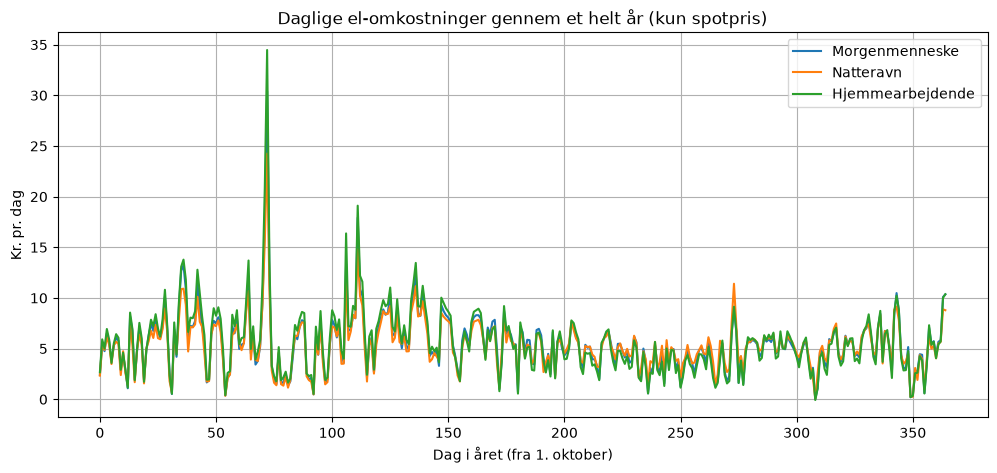

Rutinen er skrevet én gang - matrix-mekanikken skalerer til 3 husstande eller 3 millioner.
Men i virkeligheden varierer mønstrene meget mere mellem husstande, end tre stiliserede profiler kan vise.


In [24]:
# Hele året, dag for dag, alle husstande
plt.figure(figsize=(12, 5))
for i in range(3):
    plt.plot(dagsomkostninger[i], label=navne[i])
plt.title("Daglige el-omkostninger gennem et helt år (kun spotpris)")
plt.xlabel("Dag i året (fra 1. oktober)")
plt.ylabel("Kr. pr. dag")
plt.legend()
plt.grid(True)
plt.show()

print("Rutinen er skrevet én gang - matrix-mekanikken skalerer til 3 husstande eller 3 millioner.")
print("Men i virkeligheden varierer mønstrene meget mere mellem husstande, end tre stiliserede profiler kan vise.")

Læg mærke til vinterens voldsomme spidser: Årets dyreste dag ligger midt i december - den slags spidsdage skyldes typisk en kombination af kulde og vindstille (til illustration - vi har ikke vejrdata med her til at bekræfte det for netop denne dag). Prisen på den dyreste dag kan sagtens variere flere gange over prisen på en gennemsnitsdag. Det er den slags mønstre, man kun ser, når man kigger på et helt år ad gangen.

#### Drej på knapperne

* **Tilføj dig selv**: Lav din egen profil som i kapitel 6, og ret linjen med `P` til `P = np.array([morgenmenneske, natteravn, hjemmearbejdende, min_profil])`. Tilføj også et navn i `navne`-listen. Kør cellerne igen - hele analysen inkluderer nu dig.
* **Vinterens dyreste dag**: Opret en ny celle og skriv `print(np.argmax(dagsomkostninger[0]))`. Tallet er dagens nummer i året (dag 0 = 1. oktober) - hvornår ramte det?


# Kapitel 8 (efter lektion 8): Danmarks økonomi som matrix

Til sidst zoomer vi helt ud. Sektorer i en økonomi køber af *hinanden*: energisektoren bruger industriens maskiner, industrien bruger energi, servicesektoren bruger begge dele. Præcis det system beskriver **Leontiefs input-output-model** fra lektion 8 - og Danmarks Statistik vedligeholder de rigtige tabeller for hele den danske økonomi.

Her bruger vi en forenklet 3-sektor-udgave (tallene er stiliserede og afrundede; strukturen svarer til Danmarks Statistiks input-output-tabeller):


In [25]:
# Inputmatrix M: kolonne j viser, hvad 1 krones produktion i sektor j kraever fra hver sektor
sektorer = ["Energi", "Industri", "Service"]
M = np.array([
    [0.05, 0.08, 0.02],   # energi-input
    [0.15, 0.25, 0.10],   # industri-input
    [0.20, 0.20, 0.15],   # service-input
])

# Endelig efterspoergsel (mia. kr.) - forbrug, eksport osv.
D = np.array([150, 900, 1400])

In [26]:
# Kan systemet loeses? Determinanten afgoer det (lektion 8)
I = np.identity(3)
det_IM = np.linalg.det(I - M)
print(f"det(I - M) = {det_IM:.3f} - forskellig fra 0, saa systemet kan loeses")

# Leontief: X = (I - M)^-1 @ D
X = np.linalg.inv(I - M) @ D
for i in range(3):
    print(f"{sektorer[i]}: skal producere {X[i]:.0f} mia. kr. for at daekke {D[i]} mia. kr. efterspoergsel")

det(I - M) = 0.571 - forskellig fra 0, saa systemet kan loeses
Energi: skal producere 332 mia. kr. for at daekke 150 mia. kr. efterspoergsel
Industri: skal producere 1545 mia. kr. for at daekke 900 mia. kr. efterspoergsel
Service: skal producere 2089 mia. kr. for at daekke 1400 mia. kr. efterspoergsel


In [27]:
# Scenario: efterspoerslen paa energi stiger 10% - hvad sker der i HELE oekonomien?
D_ny = D.copy()
D_ny[0] = D_ny[0] * 1.10

X_ny = np.linalg.inv(I - M) @ D_ny
for i in range(3):
    print(f"{sektorer[i]}: {X[i]:.0f} -> {X_ny[i]:.0f} mia. kr. (+{X_ny[i]-X[i]:.1f})")

print("\nLaeg maerke til: ALLE sektorer vokser - fordi de leverer til hinanden.")

Energi: 332 -> 348 mia. kr. (+16.2)
Industri: 1545 -> 1549 mia. kr. (+3.9)
Service: 2089 -> 2093 mia. kr. (+4.7)

Laeg maerke til: ALLE sektorer vokser - fordi de leverer til hinanden.


#### Drej på knapperne

* **Mere energikrævende industri**: I cellen med `M`: ret `0.08` (første række, anden kolonne) til `0.20`, og kør alle tre celler igen. Hvor hårdt rammer et energichok nu?
* **Ekstremt afhængige sektorer**: Ret alle ni tal i `M` til `0.33`, og kør igen. Hold øje med `det(I - M)` - systemet er ved at "æde sig selv op". Kan du se det i tallene?

---

### Det var casen

Otte kapitler, ét spørgsmål ad gangen: fra "hvad koster strømmen lige nu?" til "hvordan hænger Danmarks økonomi sammen?". Hvert svar brugte kun den seneste lektions værktøjer - men tilsammen er det en lille, men ægte analysekæde på rigtige data. Det er det, Python kan.
